In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
c_df = pd.read_excel("/content/combined data.xlsx")

In [3]:
print(len(c_df.columns))

210


In [4]:
# dfs = pd.DataFrame()
# l = ["Jan", "Feb", "Mar", "Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
# for i in l:
#   df = pd.read_csv(f"/content/monthly_files/{i}_borough_grocery.csv")
#   df["month"] = i
#   dfs = pd.concat([dfs, df], ignore_index=True)


In [5]:
import pandas as pd

area_to_local_authority = {
    "E09000001": "City of London",
    "E09000002": "Barking and Dagenham",
    "E09000003": "Barnet",
    "E09000004": "Bexley",
    "E09000005": "Brent",
    "E09000006": "Bromley",
    "E09000007": "Camden",
    "E09000008": "Croydon",
    "E09000009": "Ealing",
    "E09000010": "Enfield",
    "E09000011": "Greenwich",
    "E09000012": "Hackney",
    "E09000013": "Hammersmith and Fulham",
    "E09000014": "Haringey",
    "E09000015": "Harrow",
    "E09000016": "Havering",
    "E09000017": "Hillingdon",
    "E09000018": "Hounslow",
    "E09000019": "Islington",
    "E09000020": "Kensington and Chelsea",
    "E09000021": "Kingston upon Thames",
    "E09000022": "Lambeth",
    "E09000023": "Lewisham",
    "E09000024": "Merton",
    "E09000025": "Newham",
    "E09000026": "Redbridge",
    "E09000027": "Richmond upon Thames",
    "E09000028": "Southwark",
    "E09000029": "Sutton",
    "E09000030": "Tower Hamlets",
    "E09000031": "Waltham Forest",
    "E09000032": "Wandsworth",
    "E09000033": "Westminster"
}

dfs = pd.DataFrame()
l = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

for i in l:
    df = pd.read_csv(f"/content/monthly_files/{i}_borough_grocery.csv")

    df["month"] = i

    df['local authority name'] = df['area_id'].map(area_to_local_authority)

    dfs = pd.concat([dfs, df], ignore_index=True)



In [6]:
for i in range(203):
  print(dfs.columns[i])

area_id
weight
weight_perc2.5
weight_perc25
weight_perc50
weight_perc75
weight_perc97.5
weight_std
weight_ci95
volume
volume_perc2.5
volume_perc25
volume_perc50
volume_perc75
volume_perc97.5
volume_std
volume_ci95
fat
fat_perc2.5
fat_perc25
fat_perc50
fat_perc75
fat_perc97.5
fat_std
fat_ci95
saturate
saturate_perc2.5
saturate_perc25
saturate_perc50
saturate_perc75
saturate_perc97.5
saturate_std
saturate_ci95
salt
salt_perc2.5
salt_perc25
salt_perc50
salt_perc75
salt_perc97.5
salt_std
salt_ci95
sugar
sugar_perc2.5
sugar_perc25
sugar_perc50
sugar_perc75
sugar_perc97.5
sugar_std
sugar_ci95
protein
protein_perc2.5
protein_perc25
protein_perc50
protein_perc75
protein_perc97.5
protein_std
protein_ci95
carb
carb_perc2.5
carb_perc25
carb_perc50
carb_perc75
carb_perc97.5
carb_std
carb_ci95
fibre
fibre_perc2.5
fibre_perc25
fibre_perc50
fibre_perc75
fibre_perc97.5
fibre_std
fibre_ci95
alcohol
alcohol_perc2.5
alcohol_perc25
alcohol_perc50
alcohol_perc75
alcohol_perc97.5
alcohol_std
alcohol_ci95
en

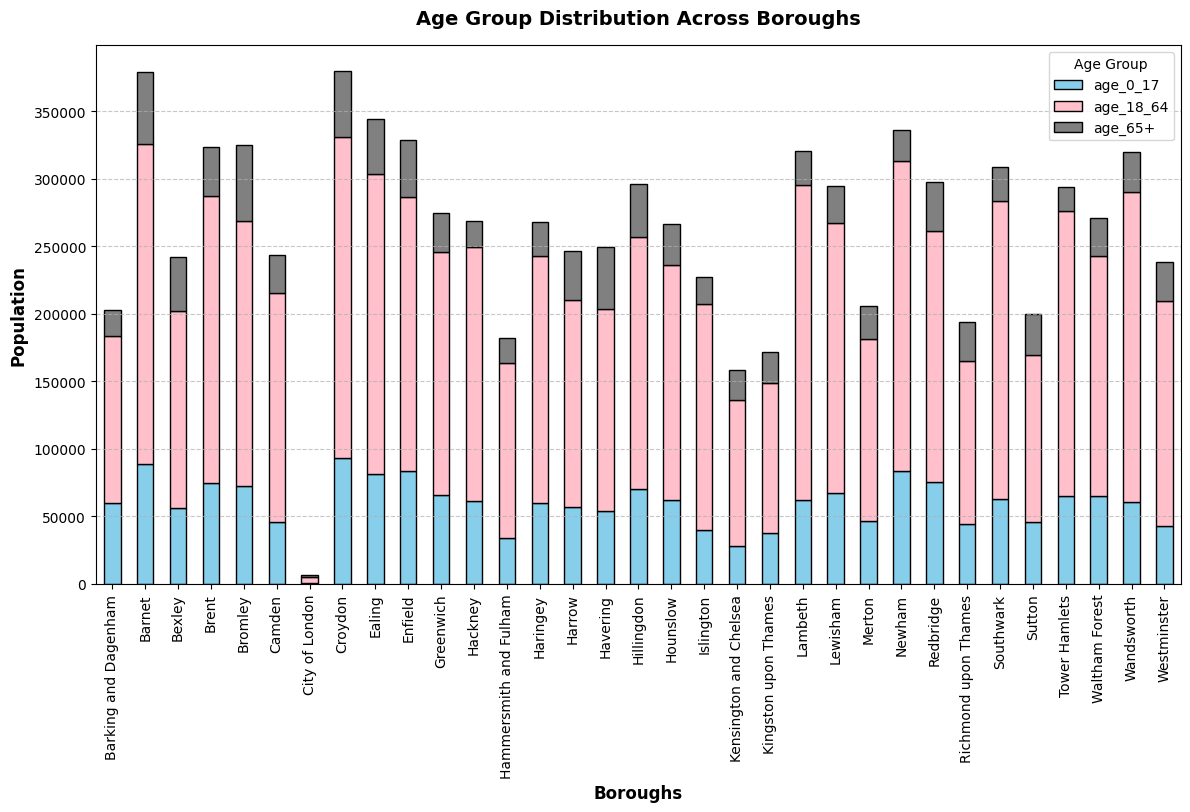

In [7]:
age_distribution = c_df.groupby("local authority name")[["age_0_17", "age_18_64", "age_65+"]].sum()

age_distribution.plot(kind="bar", stacked=True, figsize=(14, 7), color=['skyblue', 'pink','grey'], edgecolor="black")

plt.xlabel("Boroughs", fontsize=12, fontweight="bold")
plt.ylabel("Population", fontsize=12, fontweight="bold")
plt.title("Age Group Distribution Across Boroughs", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=90)
plt.legend(title="Age Group")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()



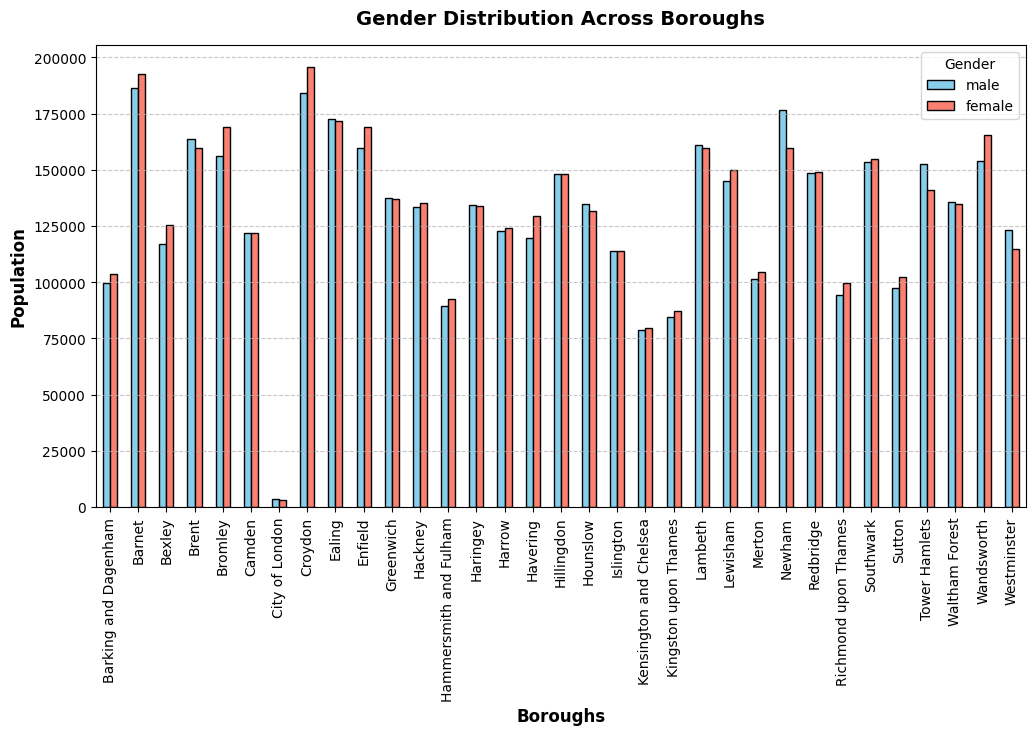

In [8]:

gender_distribution = c_df.groupby("local authority name")[["male", "female"]].sum()

gender_distribution.plot(kind="bar", figsize=(12, 6), color=['skyblue', 'salmon'], edgecolor="black")

plt.xlabel("Boroughs", fontsize=12, fontweight="bold")
plt.ylabel("Population", fontsize=12, fontweight="bold")
plt.title("Gender Distribution Across Boroughs", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=90)
plt.legend(title="Gender")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


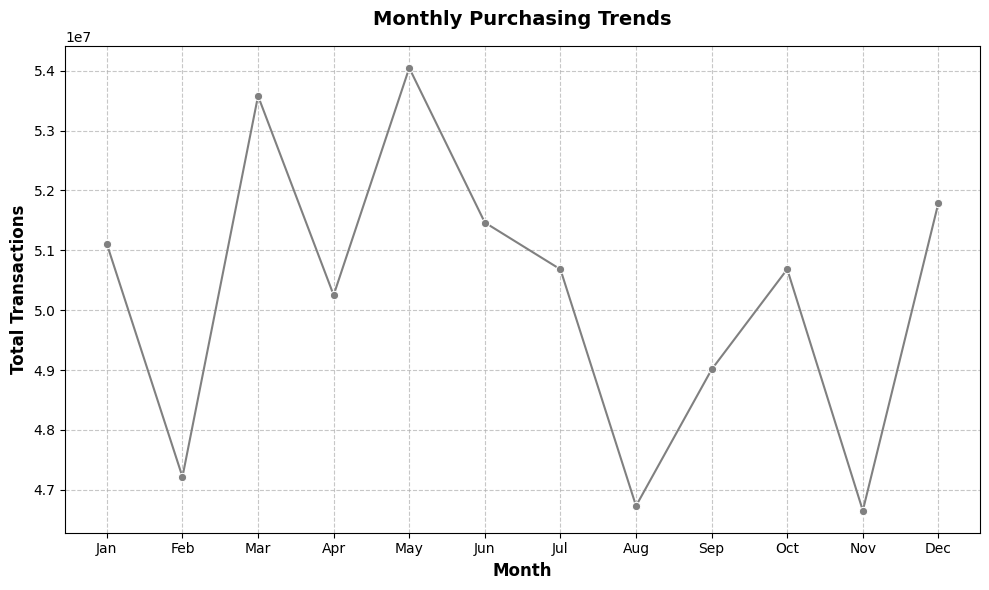

In [9]:

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

monthly_trends = dfs.groupby('month')['num_transactions'].sum().reset_index()

monthly_trends['month'] = pd.Categorical(monthly_trends['month'], categories=months_ordered, ordered=True)

monthly_trends = monthly_trends.sort_values('month')

plt.figure(figsize=(10, 6))

sns.lineplot(x='month', y='num_transactions', data=monthly_trends, marker='o', color = "gray")

plt.xlabel('Month', fontsize=12, fontweight="bold")
plt.ylabel('Total Transactions', fontsize=12, fontweight="bold")
plt.title('Monthly Purchasing Trends', fontsize=14, fontweight="bold", pad=15)

plt.xticks()
plt.grid(linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


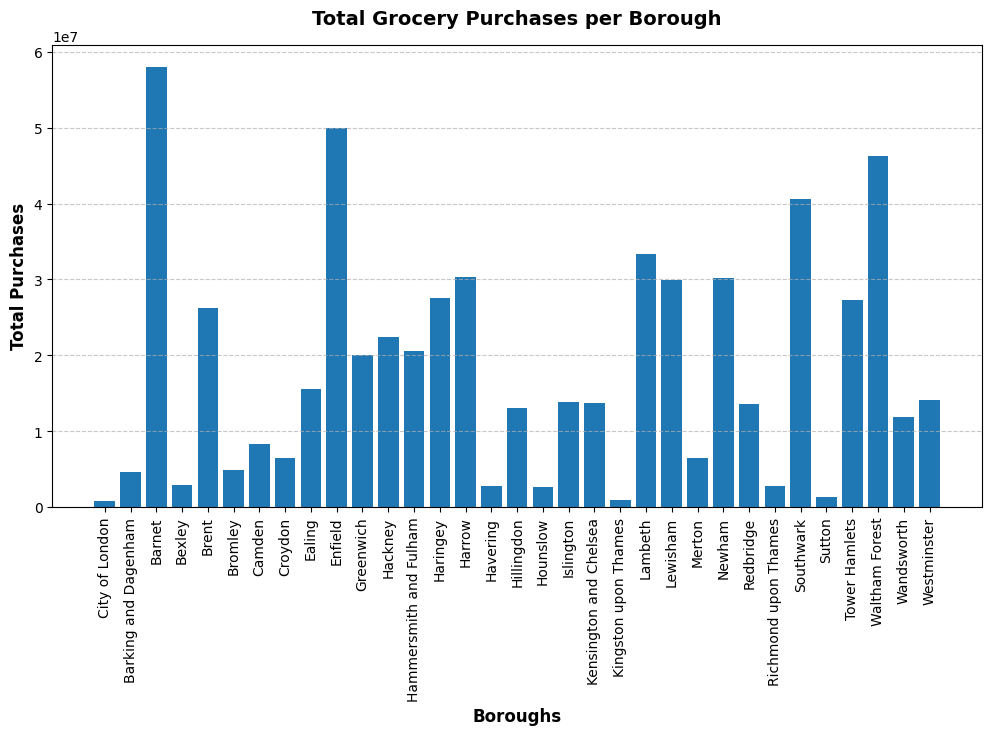

In [10]:
plt.figure(figsize=(12, 6))
plt.bar(c_df["local authority name"], c_df["num_transactions"])

plt.xlabel("Boroughs", fontsize=12, fontweight="bold")
plt.ylabel("Total Purchases", fontsize=12, fontweight="bold")
plt.title("Total Grocery Purchases per Borough" , fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [11]:
category_columns = ['f_beer', 'f_dairy', 'f_eggs', 'f_fats_oils_weight', 'f_fish', 'f_fruit_veg', 'f_grains', 'f_meat_red', 'f_poultry', 'f_readymade', 'f_sauces', 'f_soft_drinks', 'f_spirits', 'f_sweets', 'f_tea_coffee', 'f_water', 'f_wine']

category_sales = c_df[category_columns].multiply(c_df["num_transactions"], axis=0).sum()





most_sold_all_time = category_sales.idxmax()
least_sold_all_time = category_sales.idxmin()

df_may = dfs[dfs['month'] == "May"]
may_category_sales = df_may[category_columns].multiply(df_may['num_transactions'], axis=0).sum()

most_sold_may = may_category_sales.idxmax()
least_sold_may = may_category_sales.idxmin()

print("Most Sold Category Across All Months:", most_sold_all_time)
print("Least Sold Category Across All Months:", least_sold_all_time)
print("Most Sold Category in May:", most_sold_may)
print("Least Sold Category in May:", least_sold_may)

Most Sold Category Across All Months: f_fruit_veg
Least Sold Category Across All Months: f_spirits
Most Sold Category in May: f_fruit_veg
Least Sold Category in May: f_spirits


In [12]:
# category_sales = c_df.groupby(['f_beer', 'f_dairy', 'f_eggs', 'f_fats_oils_weight', 'f_fish', 'f_fruit_veg', 'f_grains', 'f_meat_red', 'f_poultry', 'f_readymade', 'f_sauces', 'f_soft_drinks', 'f_spirits', 'f_sweets', 'f_tea_coffee', 'f_water', 'f_wine'])['num_transactions'].sum()


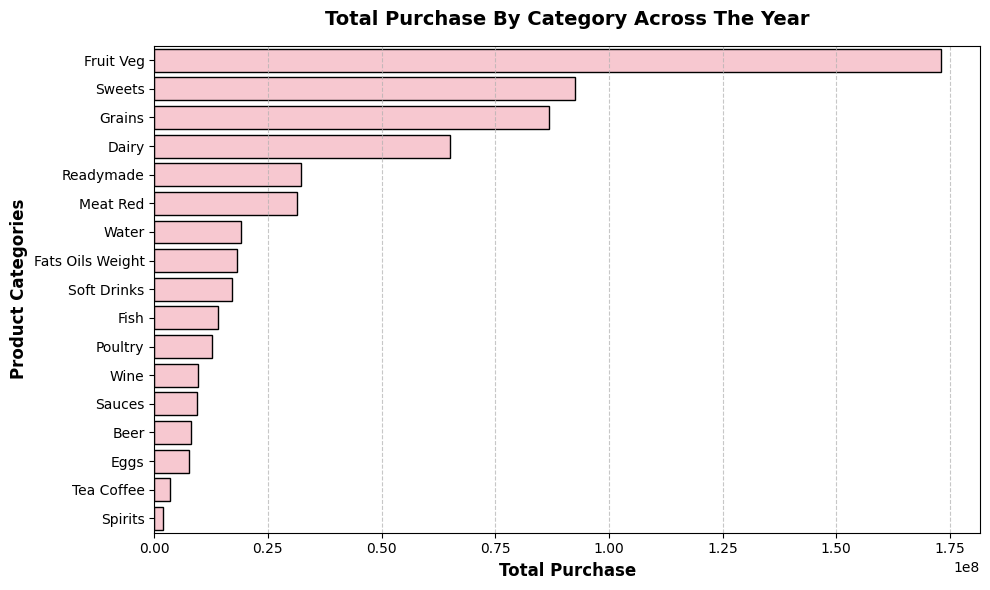

In [13]:
category_sales_sorted = category_sales.sort_values(ascending=False)
category_sales_sorted.index = category_sales_sorted.index.str.replace("f_", "").str.replace("_", " ").str.title()

plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales_sorted.values, y=category_sales_sorted.index, color ="pink", edgecolor="black")
plt.xlabel("Total Purchase", fontsize=12, fontweight="bold")
plt.ylabel("Product Categories", fontsize=12, fontweight="bold")
plt.title("Total Purchase By Category Across The Year", fontsize=14, fontweight="bold", pad=15)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

f_beer                 1.325725
f_dairy               10.787721
f_eggs                 1.270829
f_fats_oils_weight     3.003919
f_fish                 2.315375
f_fruit_veg           28.677741
f_grains              14.378899
f_meat_red             5.200667
f_poultry              2.111988
f_readymade            5.337705
f_sauces               1.559242
f_soft_drinks          2.817148
f_spirits              0.331913
f_sweets              15.334067
f_tea_coffee           0.589632
f_water                3.168194
f_wine                 1.576199
dtype: float64


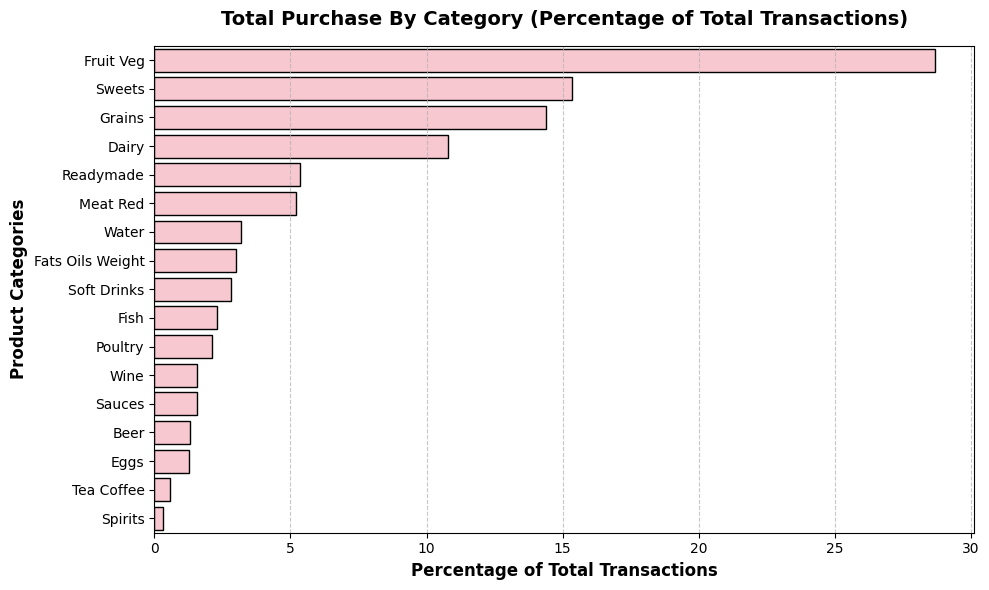

In [14]:
total_transactions = c_df['num_transactions'].sum()

category_sales_percentage = (category_sales / total_transactions) * 100
print(category_sales_percentage)
category_sales_percentage_sorted = category_sales_percentage.sort_values(ascending=False)
category_sales_percentage_sorted.index = category_sales_percentage_sorted.index.str.replace("f_", "").str.replace("_", " ").str.title()

plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales_percentage_sorted.values, y=category_sales_percentage_sorted.index, color="pink", edgecolor="black")
plt.xlabel("Percentage of Total Transactions", fontsize=12, fontweight="bold")
plt.ylabel("Product Categories", fontsize=12, fontweight="bold")
plt.title("Total Purchase By Category (Percentage of Total Transactions)", fontsize=14, fontweight="bold", pad=15)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


In [15]:
dfs['month'].unique()

array(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
       'Oct', 'Nov', 'Dec'], dtype=object)

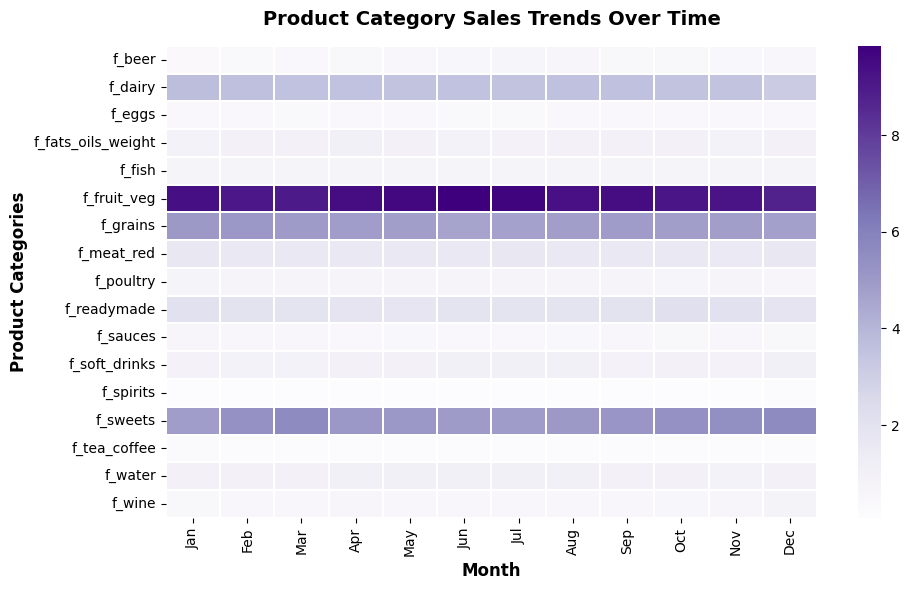

In [16]:

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

category_trends = dfs.groupby('month')[category_columns].sum().reset_index()

category_trends['month'] = pd.Categorical(category_trends['month'], categories=months_ordered, ordered=True)

category_trends = category_trends.sort_values('month')

plt.figure(figsize=(10, 6))
sns.heatmap(category_trends.set_index('month').T, cmap="Purples", linewidths=0.2, fmt=".0f")

plt.xlabel("Month", fontsize=12, fontweight="bold")
plt.ylabel("Product Categories", fontsize=12, fontweight="bold")
plt.title("Product Category Sales Trends Over Time", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

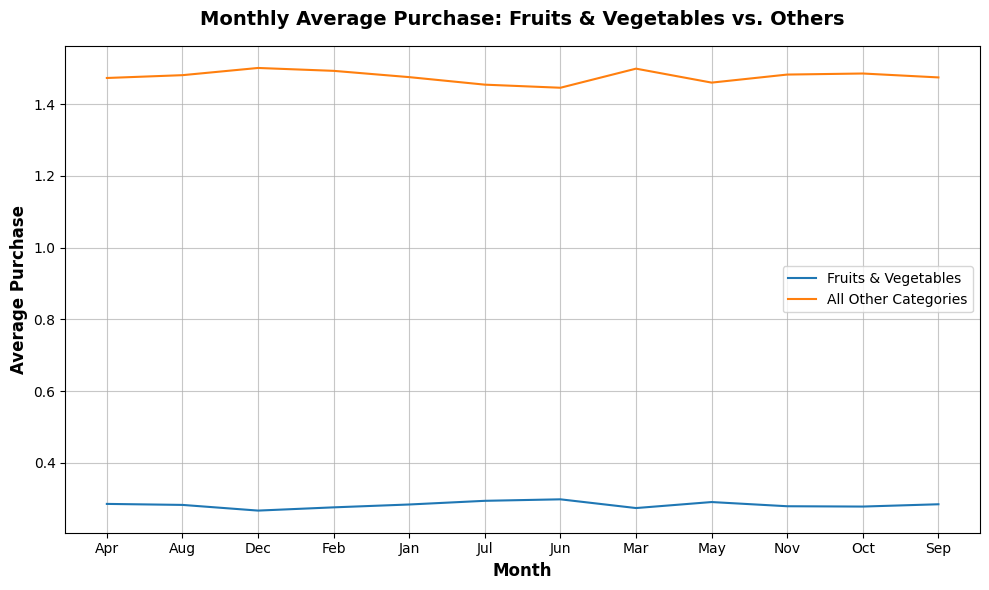

In [17]:
monthly_fruit_veg_sales = dfs.groupby('month')['f_fruit_veg'].mean()

other_categories = [col for col in category_columns if col != 'f_fruit_veg']
monthly_other_sales = dfs.groupby('month')[other_categories].sum().sum(axis=1) / len(other_categories)


plt.figure(figsize=(10, 6))
plt.plot(monthly_fruit_veg_sales.index, monthly_fruit_veg_sales.values, label='Fruits & Vegetables')
plt.plot(monthly_other_sales.index, monthly_other_sales.values, label='All Other Categories')


plt.xlabel('Month', fontsize=12, fontweight="bold")
plt.ylabel('Average Purchase', fontsize=12, fontweight="bold")
plt.title('Monthly Average Purchase: Fruits & Vegetables vs. Others', fontsize=14, fontweight="bold", pad=15)
plt.legend()
plt.grid(True, alpha = 0.7)
plt.tight_layout()

plt.show()


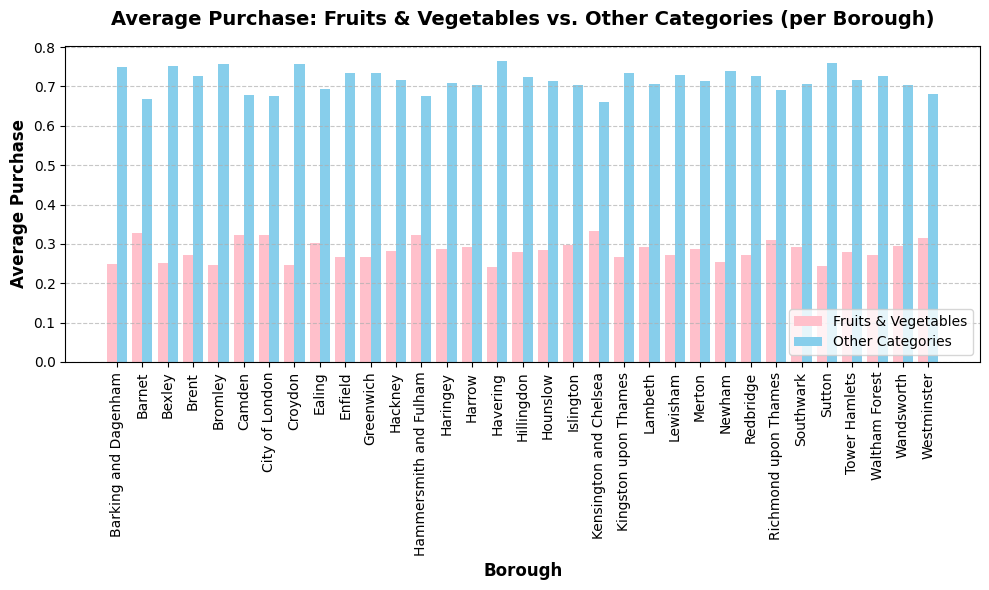

In [18]:
fruit_veg_by_borough = c_df.groupby(['local authority name'])['f_fruit_veg'].sum().reset_index()

other_categories = [col for col in category_columns if col != 'f_fruit_veg']
other_by_borough = c_df.groupby(['local authority name'])[other_categories].sum().sum(axis=1).reset_index(name='other_categories_sum')

merged_df = pd.merge(fruit_veg_by_borough, other_by_borough, on=[ 'local authority name'])

avg_purchases = merged_df.groupby('local authority name').agg({'f_fruit_veg': 'mean', 'other_categories_sum': 'mean'}).reset_index()

plt.figure(figsize=(10, 6))
X_axis = np.arange(len(avg_purchases['local authority name']))

plt.bar(X_axis - 0.2, avg_purchases['f_fruit_veg'], 0.4, label='Fruits & Vegetables', color="pink")
plt.bar(X_axis + 0.2, avg_purchases['other_categories_sum'], 0.4, label='Other Categories', color= "skyblue")

plt.xticks(X_axis, avg_purchases['local authority name'], rotation=90)
plt.xlabel('Borough', fontsize=12, fontweight="bold")
plt.ylabel('Average Purchase', fontsize=12, fontweight="bold")
plt.title('Average Purchase: Fruits & Vegetables vs. Other Categories (per Borough)', fontsize=14, fontweight="bold", pad=15)
plt.legend(loc='lower right')
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


<Figure size 1400x700 with 0 Axes>

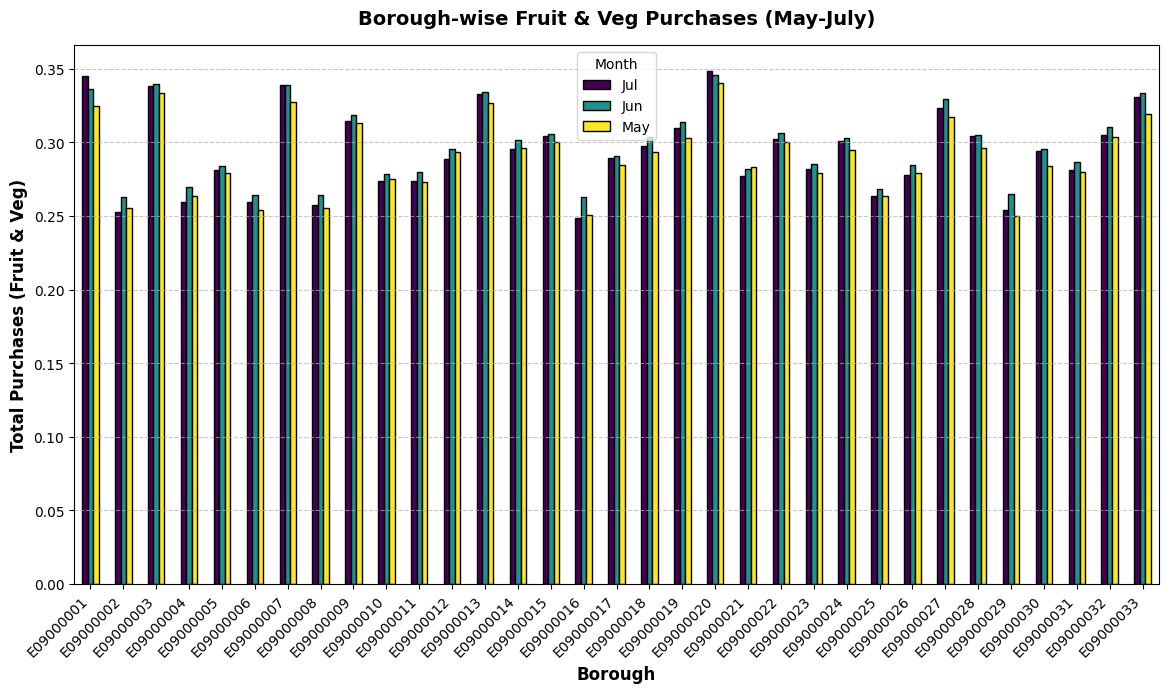

In [19]:
dfs_filtered = dfs[dfs['month'].isin(["May", "Jun", "Jul"])]

fruit_veg_trends = dfs_filtered.groupby(['area_id', 'month'])['f_fruit_veg'].sum().unstack()

plt.figure(figsize=(14, 7))
fruit_veg_trends.plot(kind='bar', figsize=(14, 7), colormap="viridis", edgecolor='black')

plt.xlabel("Borough", fontsize=12, fontweight="bold")
plt.ylabel("Total Purchases (Fruit & Veg)", fontsize=12, fontweight="bold")
plt.title("Borough-wise Fruit & Veg Purchases (May-July)", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.legend(title="Month")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

Total Sales of f_spirits: 1.2967016084833185


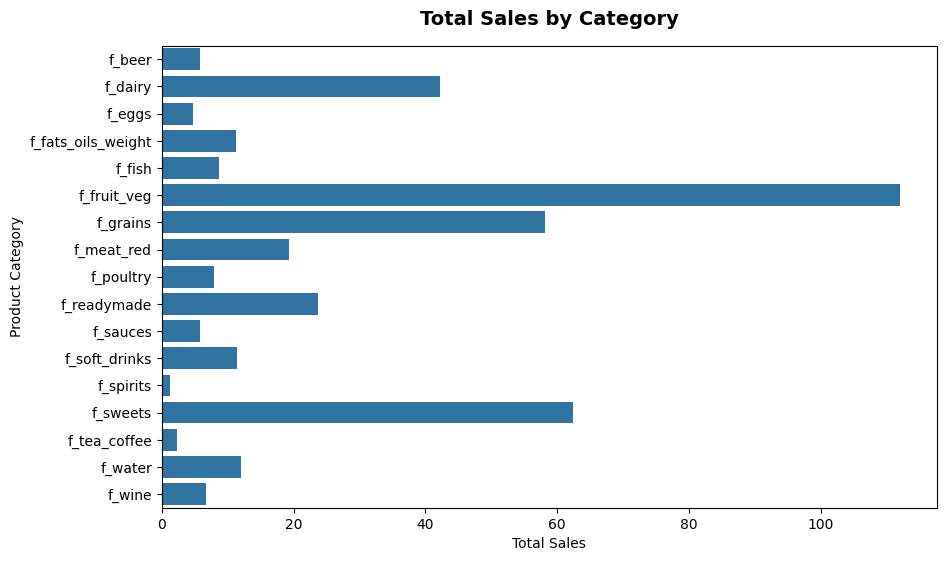

In [20]:
total_spirits_sales = dfs['f_spirits'].sum()

print(f"Total Sales of f_spirits: {total_spirits_sales}")


category_columns = ['f_beer', 'f_dairy', 'f_eggs', 'f_fats_oils_weight', 'f_fish', 'f_fruit_veg', 'f_grains', 'f_meat_red', 'f_poultry', 'f_readymade', 'f_sauces', 'f_soft_drinks', 'f_spirits', 'f_sweets', 'f_tea_coffee', 'f_water', 'f_wine']
category_sales = dfs[category_columns].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales.values, y=category_sales.index)
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.title("Total Sales by Category", fontsize=14, fontweight="bold", pad=15)
plt.show()



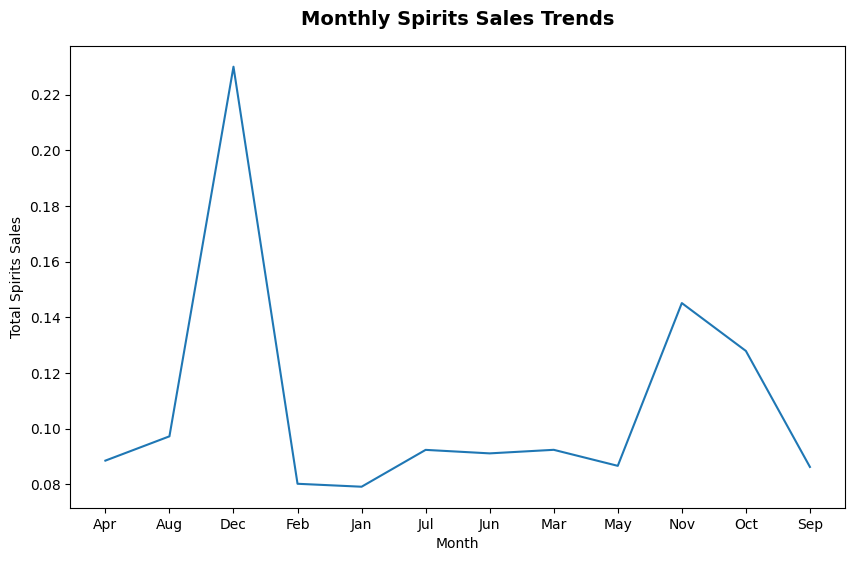

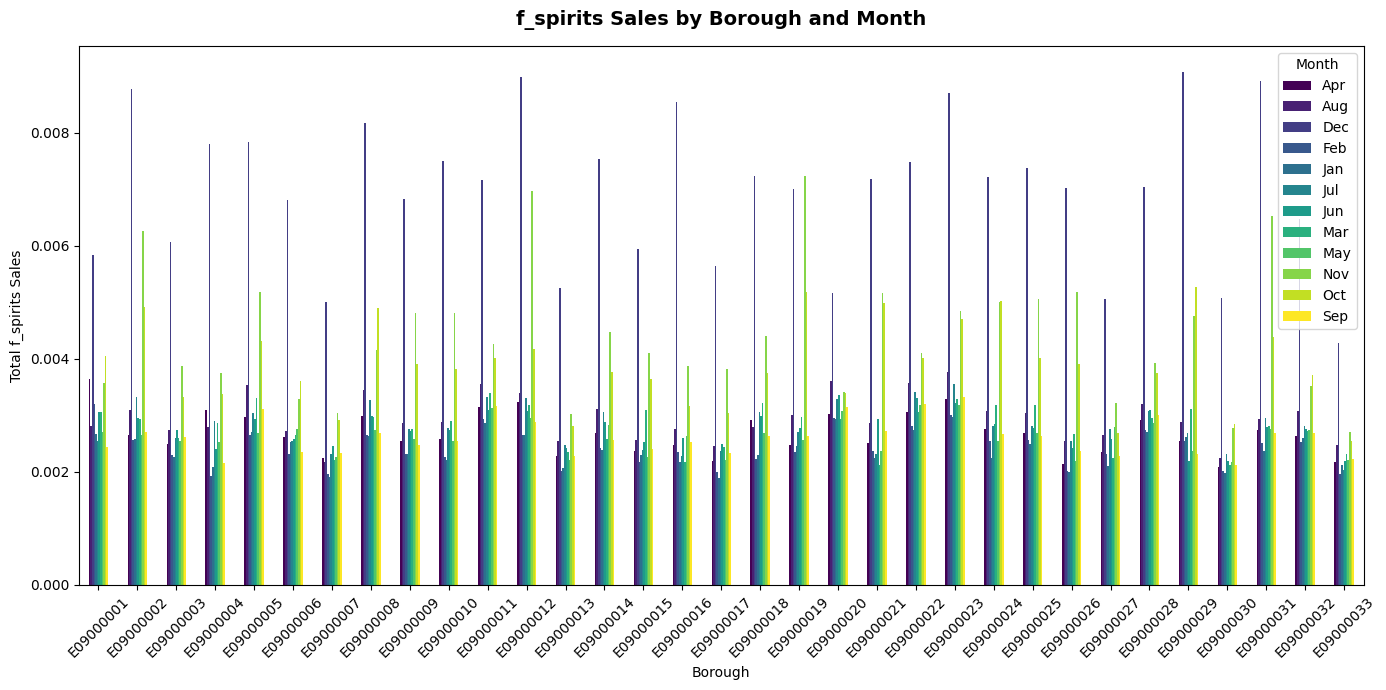

In [21]:
monthly_spirits_sales = dfs.groupby('month')['f_spirits'].sum()

plt.figure(figsize=(10, 6))
sns.lineplot(x=monthly_spirits_sales.index, y=monthly_spirits_sales.values)
plt.xlabel('Month')
plt.ylabel('Total Spirits Sales')
plt.title('Monthly Spirits Sales Trends', fontsize=14, fontweight="bold", pad=15)
plt.show()


borough_spirits_sales = dfs.groupby(['area_id','month'])['f_spirits'].sum().unstack()

borough_spirits_sales.plot(kind='bar', figsize=(14, 7), colormap="viridis")
plt.title('f_spirits Sales by Borough and Month', fontsize=14, fontweight="bold", pad=15)
plt.xlabel('Borough')
plt.ylabel('Total f_spirits Sales')
plt.xticks(rotation=45)
plt.legend(title='Month')
plt.tight_layout()
plt.show()


Total Wine Sales: 6.708005607730994
Total Beer Sales: 5.77679484572742


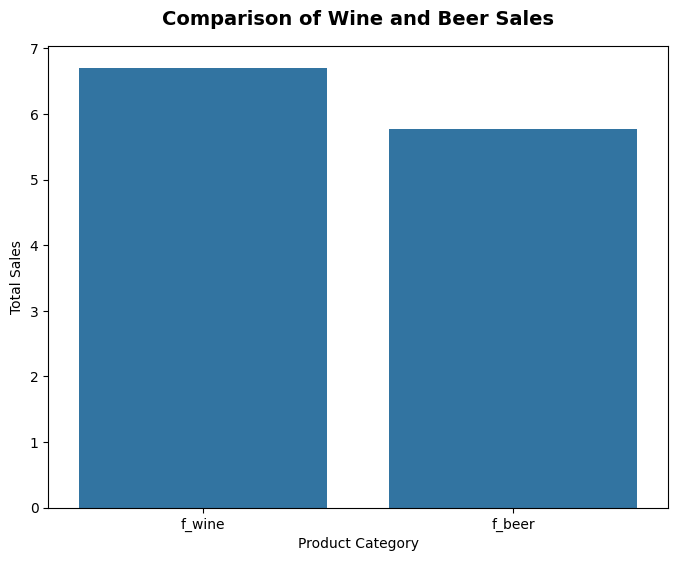

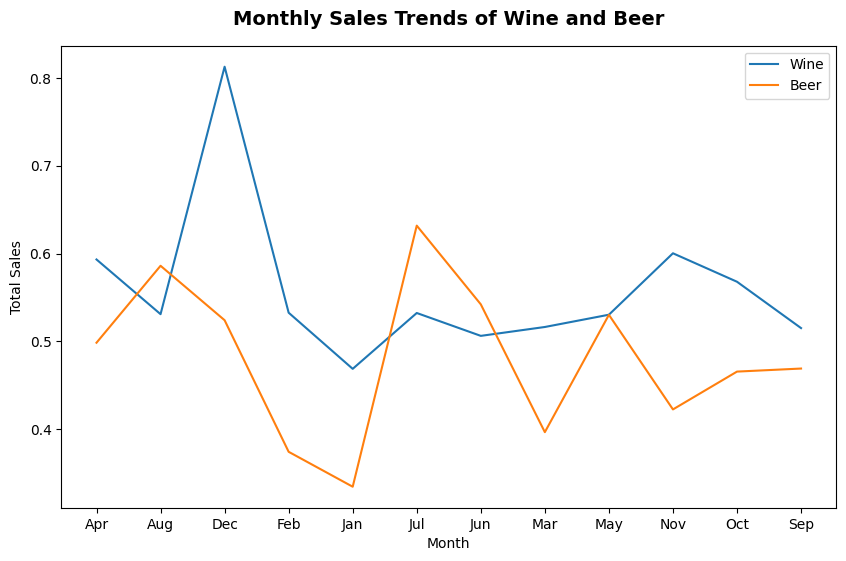

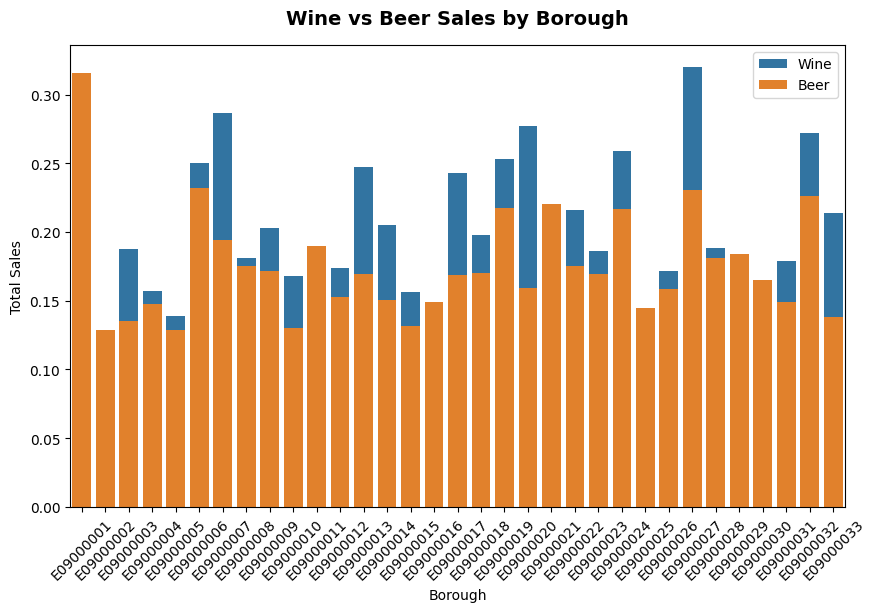

In [22]:
total_wine_sales = dfs['f_wine'].sum()
total_beer_sales = dfs['f_beer'].sum()

print(f"Total Wine Sales: {total_wine_sales}")
print(f"Total Beer Sales: {total_beer_sales}")

wine_beer_sales = dfs[['f_wine', 'f_beer']].sum()

plt.figure(figsize=(8, 6))
sns.barplot(x=wine_beer_sales.index, y=wine_beer_sales.values)
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.title("Comparison of Wine and Beer Sales", fontsize=14, fontweight="bold", pad=15)
plt.show()

monthly_wine_sales = dfs.groupby('month')['f_wine'].sum()
monthly_beer_sales = dfs.groupby('month')['f_beer'].sum()

plt.figure(figsize=(10, 6))
sns.lineplot(x=monthly_wine_sales.index, y=monthly_wine_sales.values, label='Wine')
sns.lineplot(x=monthly_beer_sales.index, y=monthly_beer_sales.values, label='Beer')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales Trends of Wine and Beer', fontsize=14, fontweight="bold", pad=15)
plt.legend()
plt.show()

borough_wine_sales = dfs.groupby('area_id')['f_wine'].sum()
borough_beer_sales = dfs.groupby('area_id')['f_beer'].sum()

plt.figure(figsize=(10,6))
sns.barplot(x=borough_wine_sales.index, y=borough_wine_sales.values, label='Wine')
sns.barplot(x=borough_beer_sales.index, y=borough_beer_sales.values, label='Beer')
plt.xlabel("Borough")
plt.ylabel("Total Sales")
plt.title("Wine vs Beer Sales by Borough", fontsize=14, fontweight="bold", pad=15)
plt.legend()
plt.xticks(rotation=45)
plt.show()


Total Tea and Coffee Sales: 2.32240092496084


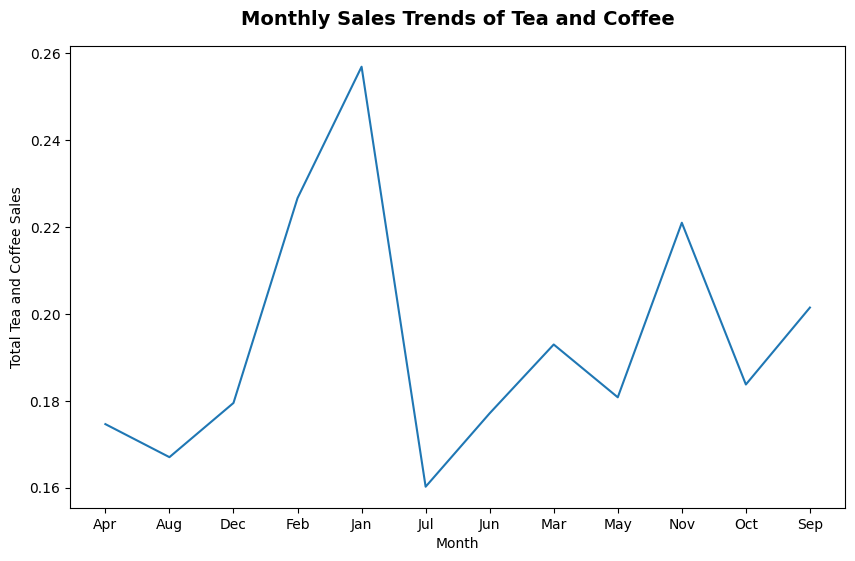

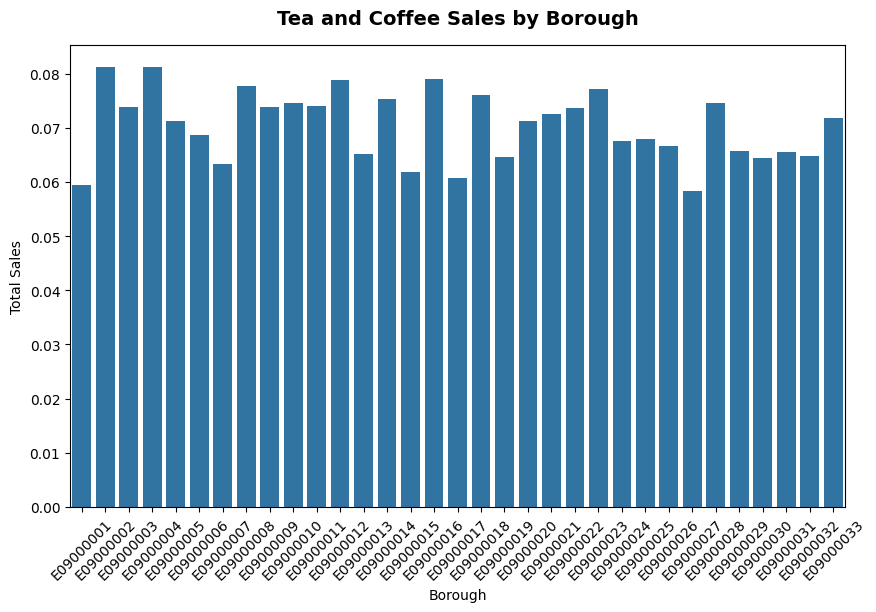

In [23]:
total_tea_sales = dfs['f_tea_coffee'].sum()

print(f"Total Tea and Coffee Sales: {total_tea_sales}")



# plt.figure(figsize=(8, 6))
# sns.barplot(x=tea_coffee_sales.index, y=tea_coffee_sales.values)
# plt.xlabel("Product Category")
# plt.ylabel("Total Sales")
# plt.title("Comparison of Tea and Coffee Sales")
# plt.show()

monthly_tea_coffee_sales = dfs.groupby('month')['f_tea_coffee'].sum()

plt.figure(figsize=(10, 6))
sns.lineplot(x=monthly_tea_coffee_sales.index, y=monthly_tea_coffee_sales.values)
plt.xlabel('Month')
plt.ylabel('Total Tea and Coffee Sales')
plt.title('Monthly Sales Trends of Tea and Coffee', fontsize=14, fontweight="bold", pad=15)
plt.show()

borough_tea_coffee_sales = dfs.groupby('area_id')['f_tea_coffee'].sum()

plt.figure(figsize=(10,6))
sns.barplot(x=borough_tea_coffee_sales.index, y=borough_tea_coffee_sales.values)
plt.xlabel("Borough")
plt.ylabel("Total Sales")
plt.title("Tea and Coffee Sales by Borough", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=45)
plt.show()


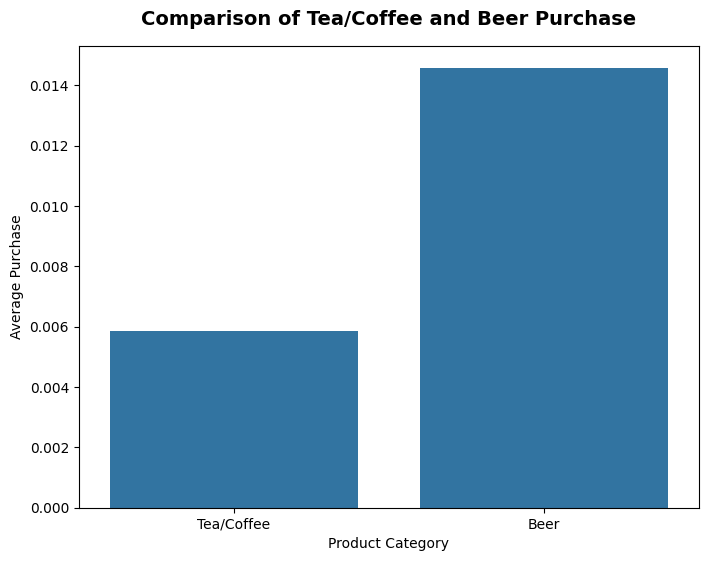

In [24]:

total_tea_coffee_sales = dfs['f_tea_coffee'].mean()
total_beer_sales = dfs['f_beer'].mean()

# print(f"Total Tea and Coffee Sales: {total_tea_coffee_sales}")
# print(f"Total Beer Sales: {total_beer_sales}")

tc_beer_sales = pd.DataFrame({'Category': ['Tea/Coffee', 'Beer'],
                            'Sales': [total_tea_coffee_sales, total_beer_sales]})

plt.figure(figsize=(8, 6))
sns.barplot(x='Category', y='Sales', data=tc_beer_sales)
plt.xlabel("Product Category")
plt.ylabel("Average Purchase")
plt.title("Comparison of Tea/Coffee and Beer Purchase", fontsize=14, fontweight="bold", pad=15)
plt.show()


# # Analyze tea/coffee and beer purchase trends over time
# monthly_tea_coffee_sales = dfs.groupby('month')['f_tea_coffee'].sum().reset_index()
# monthly_beer_sales = dfs.groupby('month')['f_beer'].sum().reset_index()

# # Define months in correct order
# months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
#                   'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# # Convert month to categorical with correct order
# monthly_beer_sales['month'] = pd.Categorical(monthly_beer_sales['month'], categories=months_ordered, ordered=True)
# monthly_tea_coffee_sales['month'] = pd.Categorical(monthly_tea_coffee_sales['month'], categories=months_ordered, ordered=True)

# # Sort by month order
# monthly_beer_sales = monthly_beer_sales.sort_values('month')
# monthly_tea_coffee_sales = monthly_tea_coffee_sales.sort_values('month')

# # Plot the trends
# plt.figure(figsize=(10, 6))

# sns.lineplot(x='month', y='f_tea_coffee', data=monthly_tea_coffee_sales, label='Tea/Coffee', marker='o')

# sns.lineplot(x='month', y='f_beer', data=monthly_beer_sales, label='Beer', marker='o')

# plt.xlabel('Month', fontsize=12)
# plt.ylabel('Total Purchases', fontsize=12)
# plt.title('Monthly Purchase Trends of Tea/Coffee and Beer', fontsize=14, fontweight="bold", pad=15)

# plt.legend()
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()


# borough_tea_coffee_sales = dfs.groupby('area_id')['f_tea_coffee'].sum()
# borough_beer_sales = dfs.groupby('area_id')['f_beer'].sum()

# plt.figure(figsize=(10,6))
# sns.barplot(x=borough_tea_coffee_sales.index, y=borough_tea_coffee_sales.values, label='Tea/Coffee')
# sns.barplot(x=borough_beer_sales.index, y=borough_beer_sales.values, label='Beer')
# plt.xlabel("Borough")
# plt.ylabel("Total Sales")
# plt.title("Tea/Coffee vs Beer Sales by Borough", fontsize=14, fontweight="bold", pad=15)
# plt.legend()
# plt.xticks(rotation=45)
# plt.show()


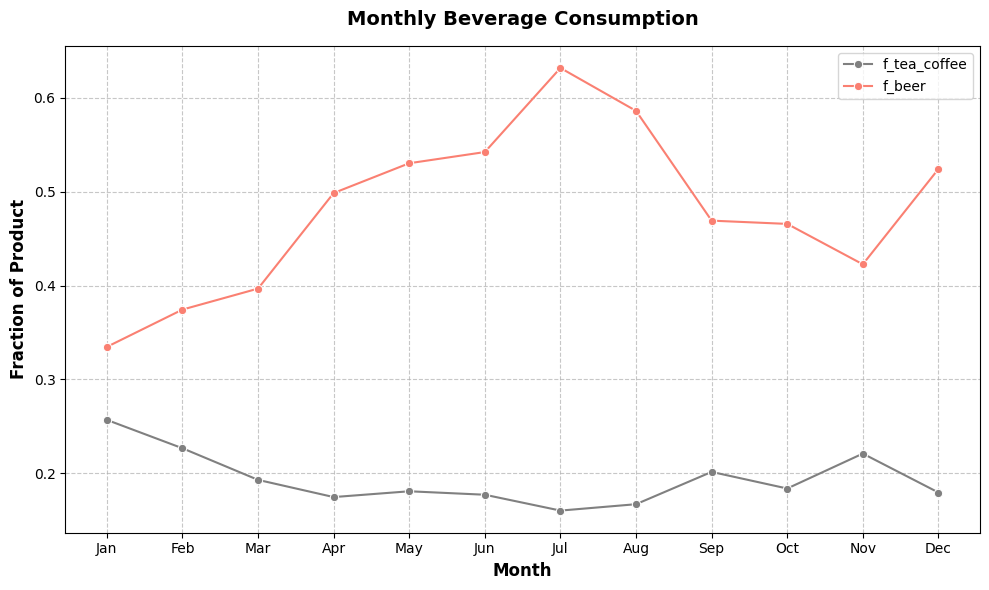

In [25]:

monthly_tea_coffee_sales = dfs.groupby('month')['f_tea_coffee'].sum().reset_index()
monthly_beer_sales = dfs.groupby('month')['f_beer'].sum().reset_index()

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Convert month to categorical with correct order
monthly_beer_sales['month'] = pd.Categorical(monthly_beer_sales['month'], categories=months_ordered, ordered=True)
monthly_tea_coffee_sales['month'] = pd.Categorical(monthly_tea_coffee_sales['month'], categories=months_ordered, ordered=True)

monthly_beer_sales = monthly_beer_sales.sort_values('month')
monthly_tea_coffee_sales = monthly_tea_coffee_sales.sort_values('month')

plt.figure(figsize=(10, 6))

sns.lineplot(x='month', y='f_tea_coffee', data=monthly_tea_coffee_sales, label='f_tea_coffee', marker='o', color ="grey")

sns.lineplot(x='month', y='f_beer', data=monthly_beer_sales, label='f_beer', marker='o', color="salmon")

plt.xlabel('Month', fontsize=12,  fontweight="bold")
plt.ylabel('Fraction of Product', fontsize=12,  fontweight="bold")
plt.title('Monthly Beverage Consumption', fontsize=14, fontweight="bold", pad=15)

plt.legend()
plt.xticks()
plt.tight_layout()
plt.grid(linestyle="--", alpha=0.7)
plt.show()


<ipython-input-26-7946b13ce473>:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


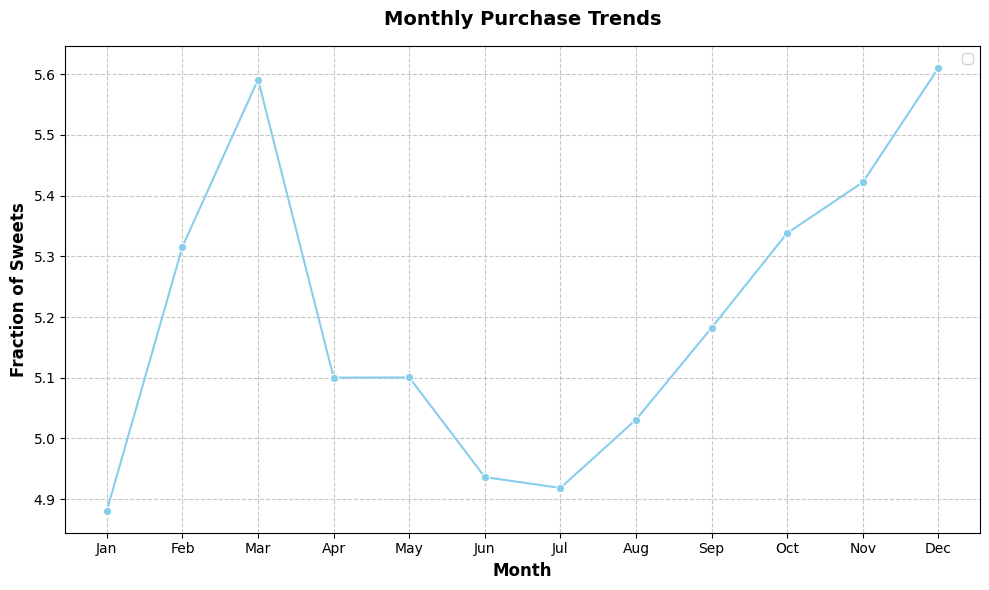

In [26]:
monthly_sugar_sales = dfs.groupby('month')['f_sweets'].sum().reset_index()

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

monthly_sugar_sales['month'] = pd.Categorical(monthly_sugar_sales['month'], categories=months_ordered, ordered=True)

monthly_sugar_sales = monthly_sugar_sales.sort_values('month')

plt.figure(figsize=(10, 6))

sns.lineplot(x='month', y='f_sweets', data=monthly_sugar_sales, marker='o', color ="skyblue")

plt.xlabel('Month', fontsize=12,  fontweight="bold")
plt.ylabel('Fraction of Sweets', fontsize=12,  fontweight="bold")
plt.title('Monthly Purchase Trends', fontsize=14, fontweight="bold", pad=15)

plt.legend()
plt.xticks()
plt.tight_layout()
plt.grid(linestyle="--", alpha=0.7)
plt.show()


In [27]:
print(dfs['energy_tot'])

0      163.438979
1      184.087087
2      167.780819
3      183.523434
4      178.125580
          ...    
391    201.294298
392    191.741615
393    191.256676
394    186.780950
395    182.035493
Name: energy_tot, Length: 396, dtype: float64


<ipython-input-28-3e2b4cdf9e36>:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


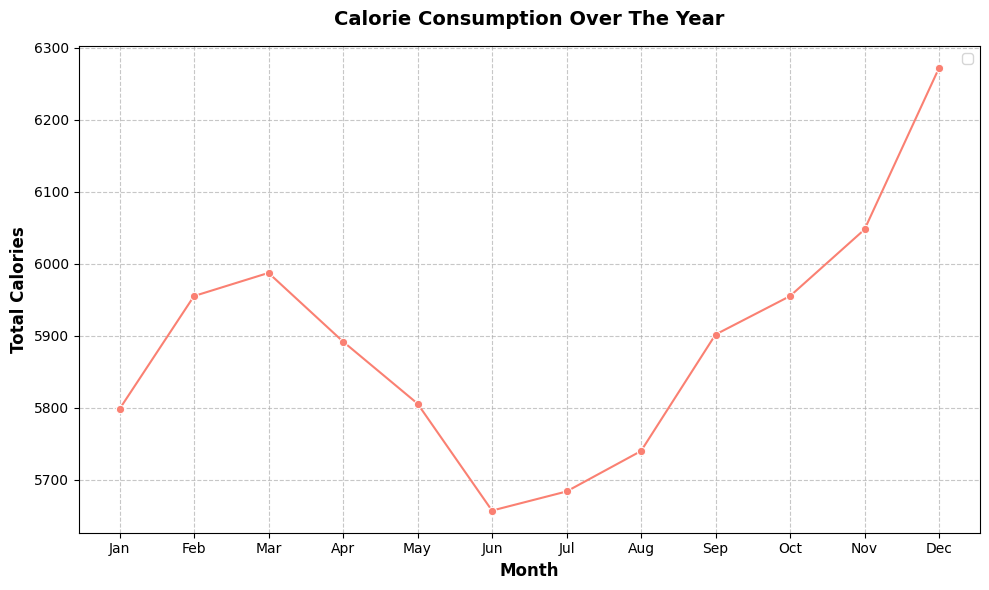

In [28]:
monthly_sugar_sales = dfs.groupby('month')['energy_tot'].sum().reset_index()

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

monthly_sugar_sales['month'] = pd.Categorical(monthly_sugar_sales['month'], categories=months_ordered, ordered=True)

monthly_sugar_sales = monthly_sugar_sales.sort_values('month')

plt.figure(figsize=(10, 6))

sns.lineplot(x='month', y='energy_tot', data=monthly_sugar_sales, marker='o', color ="salmon")

plt.xlabel('Month', fontsize=12,  fontweight="bold")
plt.ylabel('Total Calories', fontsize=12,  fontweight="bold")
plt.title('Calorie Consumption Over The Year', fontsize=14, fontweight="bold", pad=15)

plt.legend()
plt.xticks()
plt.tight_layout()
plt.grid(linestyle="--", alpha=0.7)
plt.show()


<ipython-input-29-4a823b623820>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['month'] = pd.Categorical(df2['month'], categories=months_ordered, ordered=True)
<ipython-input-29-4a823b623820>:40: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df2[df2["name"] == category].pivot_table(index="local authority name", columns="month", values="value", aggfunc="mean"),
<ipython-input-29-4a823b623820>:40: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain

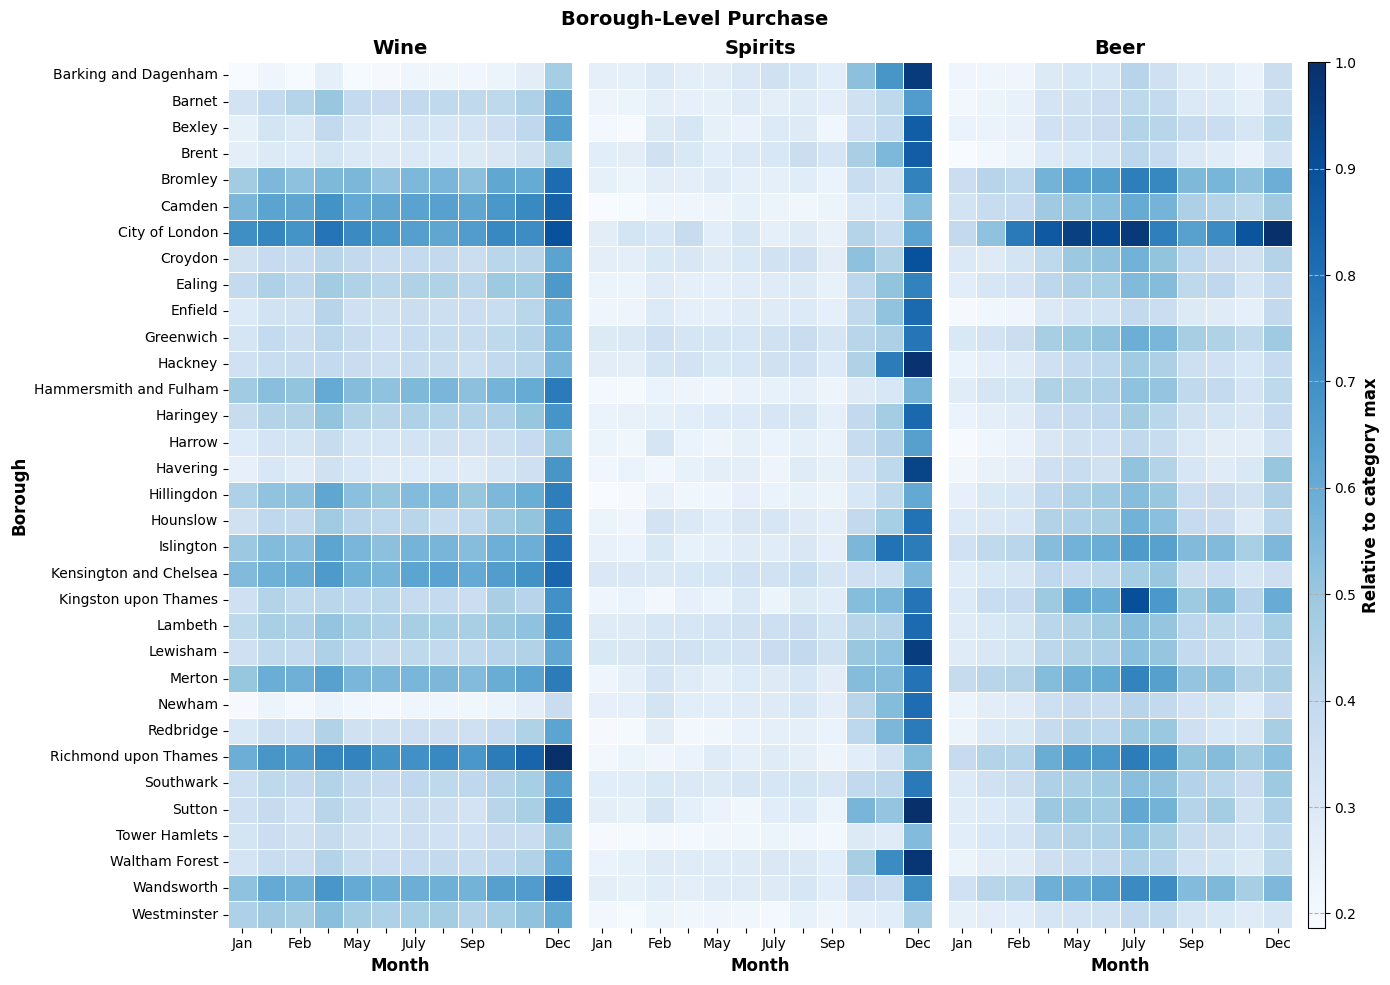

In [29]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df2 = dfs[["local authority name", "month", "f_wine", "f_spirits", "f_beer"]]

# Convert month to categorical with correct order
df2['month'] = pd.Categorical(df2['month'], categories=months_ordered, ordered=True)

df2 = df2.sort_values('month')

# Reshape data to long format
df2 = df2.melt(id_vars=["local authority name", "month"], var_name="name", value_name="value")

# Clean category names
df2["name"] = df2["name"].apply(lambda x: re.sub(r"f_", "", x).replace("_", " ").title())

# Normalize values within each category
df2["value"] = df2.groupby("name")["value"].transform(lambda x: x / x.max())

# Set up figure with a shared color bar
fig = plt.figure(figsize=(14, 10))
gs = GridSpec(1, 4, width_ratios=[1, 1, 1, 0.05])  # Last column is for color bar

axes = [fig.add_subplot(gs[i]) for i in range(3)]
cbar_ax = fig.add_subplot(gs[3])  # Separate color bar axis

categories = ["Wine", "Spirits", "Beer"]
heatmaps = []

for i, (ax, category) in enumerate(zip(axes, categories)):
    heatmap = sns.heatmap(
        df2[df2["name"] == category].pivot_table(index="local authority name", columns="month", values="value", aggfunc="mean"),
        cmap="Blues",
        linewidths=0.5,
        cbar=False,  # Hide individual color bars
        ax=ax
    )
    heatmaps.append(heatmap)

    ax.set_xlabel("Month", fontsize=12, fontweight="bold")
    ax.set_title(f"{category}", fontsize=14, fontweight="bold")
    ax.set_xticklabels(["Jan", "", "Feb", "", "May", "", "July", "", "Sep", "", "", "Dec"],rotation =0)

    # Show borough names only for the first heatmap
    if i == 0:
        ax.set_ylabel("Borough", fontsize=12, fontweight="bold")
    else:
        ax.set_ylabel("")
        ax.set_yticks([])  # Hide y-axis labels for second and third heatmaps


cbar = fig.colorbar(heatmaps[0].collections[0], cax=cbar_ax)
cbar.ax.set_ylabel('Relative to category max', fontsize=12, fontweight="bold")

plt.suptitle("Borough-Level Purchase", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.grid(linestyle="--", alpha=1)
plt.show()


<ipython-input-30-82e9763ed92c>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['month'] = pd.Categorical(df2['month'], categories=months_ordered, ordered=True)
<ipython-input-30-82e9763ed92c>:33: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  sns.heatmap(df2[df2["name"] == category].pivot_table(index="local authority name", columns="month", values="value", aggfunc=np.mean),
<ipython-input-30-82e9763ed92c>:33: FutureWarning: The provided callable <function mean at 0x789fced6ab60> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be

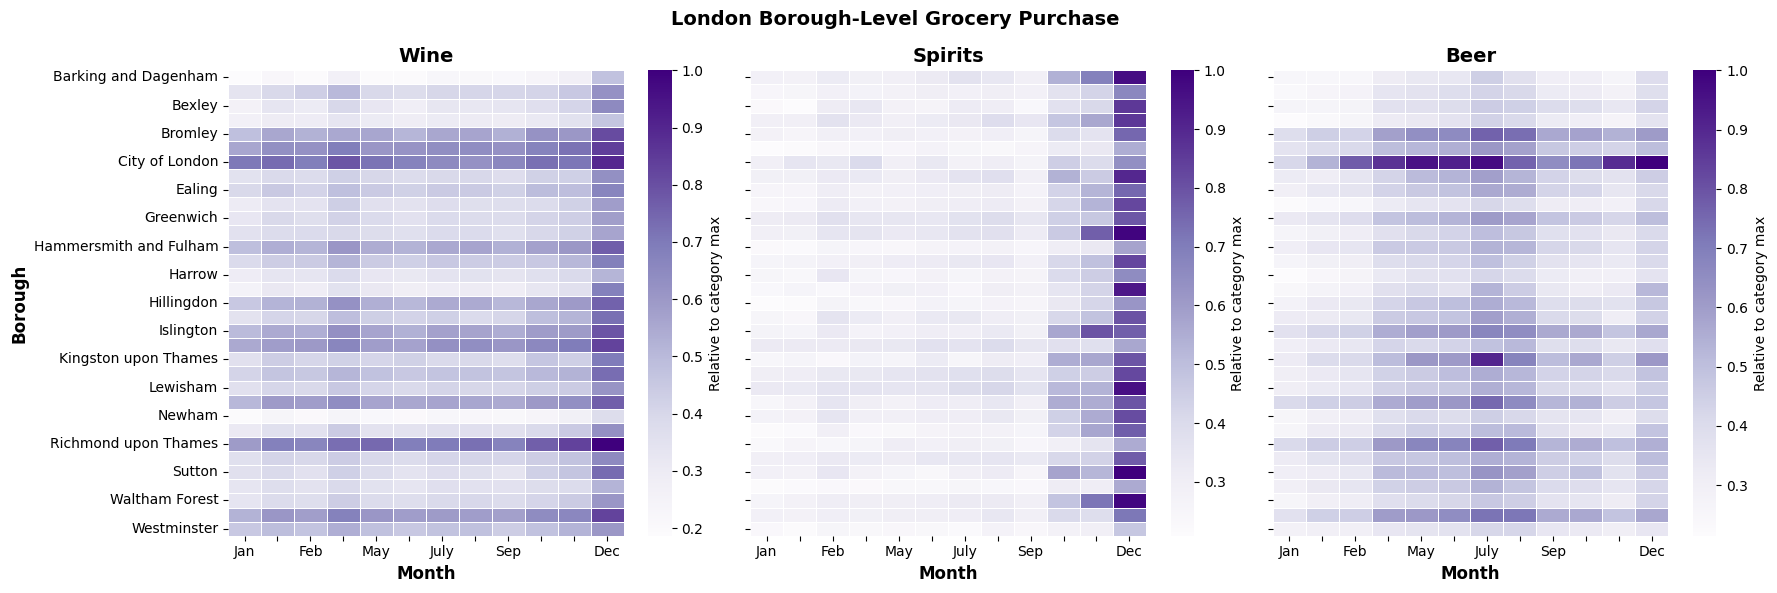

In [30]:
import re
from matplotlib.patches import Rectangle


months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']



df2 = dfs[["local authority name", "month", "f_wine", "f_spirits", "f_beer"]]
# Convert month to categorical with correct order
df2['month'] = pd.Categorical(df2['month'], categories=months_ordered, ordered=True)

# Sort by month order
df2 = df2.sort_values('month')
# Reshape data to long format
df2 = df2.melt(id_vars=["local authority name", "month"], var_name="name", value_name="value")

# Clean category names
df2["name"] = df2["name"].apply(lambda x: re.sub(r"f_", "", x).replace("_", " ").title())

# Load borough reference data (assuming it's available as 'br.csv')
# br = pd.read_csv("/mnt/data/br.csv")
# df2 = df2.merge(br, on="area_id", how="left")

# Normalize values within each category
df2["value"] = df2.groupby("name")["value"].transform(lambda x: x / x.max())

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
categories = ["Wine", "Spirits", "Beer"]

for ax, category in zip(axes, categories):
    sns.heatmap(df2[df2["name"] == category].pivot_table(index="local authority name", columns="month", values="value", aggfunc=np.mean),
                cmap="Purples", linewidths=0.5, cbar_kws={'label': 'Relative to category max'}, ax=ax)
    ax.set_xlabel("Month",fontsize=12, fontweight="bold")
    ax.set_ylabel("Borough" if category == "Wine" else "", fontsize=12, fontweight="bold")
    ax.set_title(f"{category}", fontsize=14, fontweight="bold")
    # ax.set_xticks(np.linspace(1, 12, num=12))
    ax.set_xticklabels(["Jan", "", "Feb", "", "May", "", "July", "", "Sep", "", "", "Dec"])
    # ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.suptitle("London Borough-Level Grocery Purchase", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

 Seasonal Trends
Wine: Higher purchases towards December, likely due to holiday celebrations. Tesco could prepare for increased demand by stocking up in advance.
Spirits: Generally lower compared to beer and wine, but peaks in December suggest festive purchases.
Beer: Higher relative sales throughout the year, with spikes in summer and December. Summer promotions could be effective.
2. Borough-Level Insights
Some boroughs show significantly higher purchases than others. Tesco could analyze store-specific promotions, stocking, or pricing strategies to maximize sales in high-demand areas.
Boroughs with consistently low sales may need targeted marketing efforts or reassessment of product placement.
3. Stocking & Promotion Strategies
December Peak: Ensure sufficient stock of all categories, particularly wine and spirits.
Summer Sales: Consider beer promotions in warm months, as data suggests higher demand.
Borough-Specific Promotions: Tailor discounts or deals in high-consumption boroughs to further drive sales.

Top boroughs with the highest purchases:
    name    area_id     value
0   Beer  E09000001  1.000000
67  Wine  E09000002  1.000000
68  Wine  E09000003  1.000000
69  Wine  E09000004  1.000000
70  Wine  E09000005  1.000000
71  Wine  E09000006  1.000000
72  Wine  E09000007  1.000000
73  Wine  E09000008  1.000000
74  Wine  E09000009  1.000000
75  Wine  E09000010  1.000000
76  Wine  E09000011  1.000000
77  Wine  E09000012  1.000000
78  Wine  E09000013  1.000000
79  Wine  E09000014  1.000000
80  Wine  E09000015  1.000000
81  Wine  E09000016  1.000000
82  Wine  E09000017  1.000000
83  Wine  E09000018  1.000000
84  Wine  E09000019  1.000000
85  Wine  E09000020  1.000000
86  Wine  E09000021  0.839237
87  Wine  E09000022  1.000000
88  Wine  E09000023  1.000000
89  Wine  E09000024  1.000000
90  Wine  E09000025  0.912095
91  Wine  E09000026  1.000000
92  Wine  E09000027  1.000000
93  Wine  E09000028  1.000000
94  Wine  E09000029  1.000000
95  Wine  E09000030  1.000000
96  Wine  E09000031  1.000000

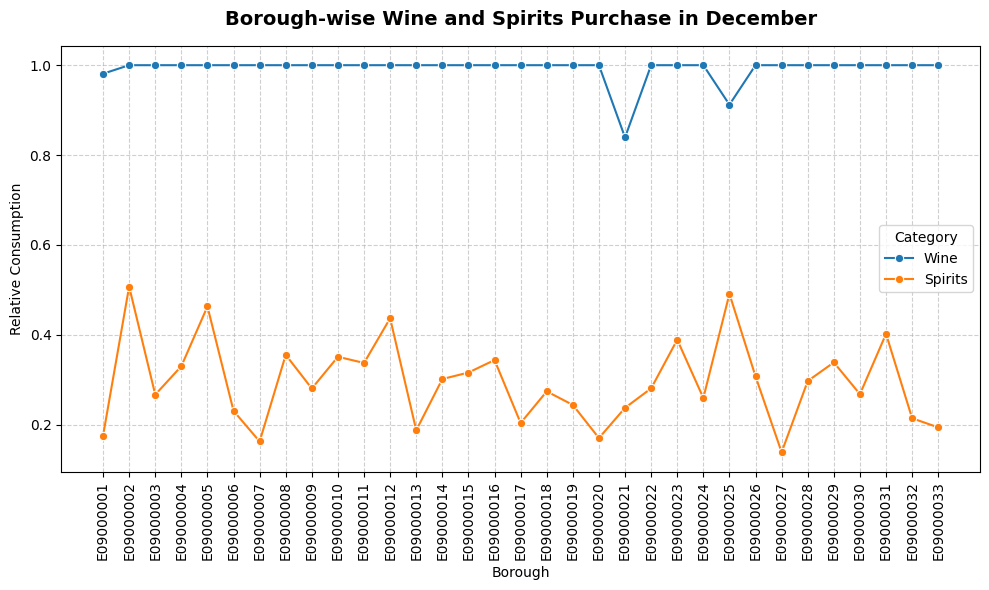

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re

df2 = dfs[["area_id", "month", "f_wine", "f_spirits", "f_beer"]]

df2 = df2.melt(id_vars=["area_id", "month"], var_name="name", value_name="value")

df2["name"] = df2["name"].apply(lambda x: re.sub(r"f_", "", x).replace("_", " ").title())

df2["value"] = df2.groupby("area_id")["value"].transform(lambda x: x / x.max())

december_data = df2[df2["month"] == "Dec"]


top_boroughs = december_data.groupby(["name", "area_id"]).agg({"value": "sum"}).reset_index()
top_boroughs = top_boroughs.loc[top_boroughs.groupby("area_id")["value"].idxmax()]
print("Top boroughs with the highest purchases:")
print(top_boroughs)

plt.figure(figsize=(10, 6))

for category in ["Wine", "Spirits"]:
    data = december_data[december_data["name"] == category]
    data = data.groupby("area_id")["value"].mean().reset_index()
    sns.lineplot(x="area_id", y="value", data=data, marker="o", label=category)

plt.ylabel("Relative Consumption")
plt.xlabel("Borough")
plt.title("Borough-wise Wine and Spirits Purchase in December", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=90)
plt.legend(title="Category")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

<ipython-input-32-9c8626af04e5>:16: FutureWarning: The provided callable <function mean at 0x789fced6ab60> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  g = sns.heatmap(df2.pivot_table(index="area_id", columns="month", values="value", aggfunc=np.mean),


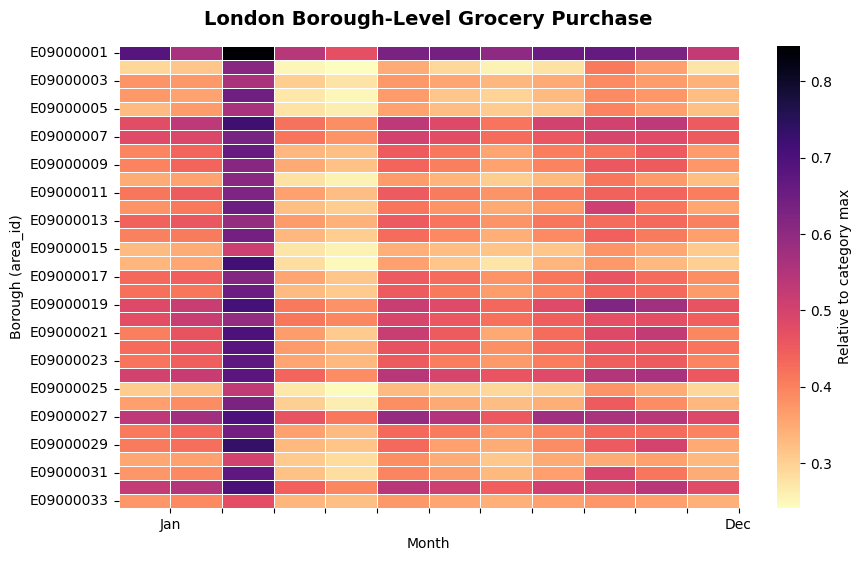

In [32]:
df2 = df[["area_id", "month", "f_wine", "f_spirits", "f_beer"]]

df2 = dfs[["area_id", "month", "f_wine", "f_spirits", "f_beer"]]

df2 = df2.melt(id_vars=["area_id", "month"], var_name="category", value_name="value")

df2["category"] = df2["category"].str.replace("f_", "").str.replace("_", " ").str.title()

df2["value"] = df2.groupby("category")['value'].transform(lambda x: x / x.max())

plt.figure(figsize=(10, 6))
g = sns.heatmap(df2.pivot_table(index="area_id", columns="month", values="value", aggfunc=np.mean),
                cmap="magma_r", linewidths=0.5, cbar_kws={'label': 'Relative to category max'})
plt.xlabel("Month")
plt.ylabel("Borough (area_id)")
plt.title("London Borough-Level Grocery Purchase", fontsize=14, fontweight="bold", pad=15)
plt.xticks(ticks=np.linspace(1, 12, num=12), labels=["Jan", "", "", "", "", "", "", "", "", "", "", "Dec"])
plt.yticks(rotation=0)
plt.show()


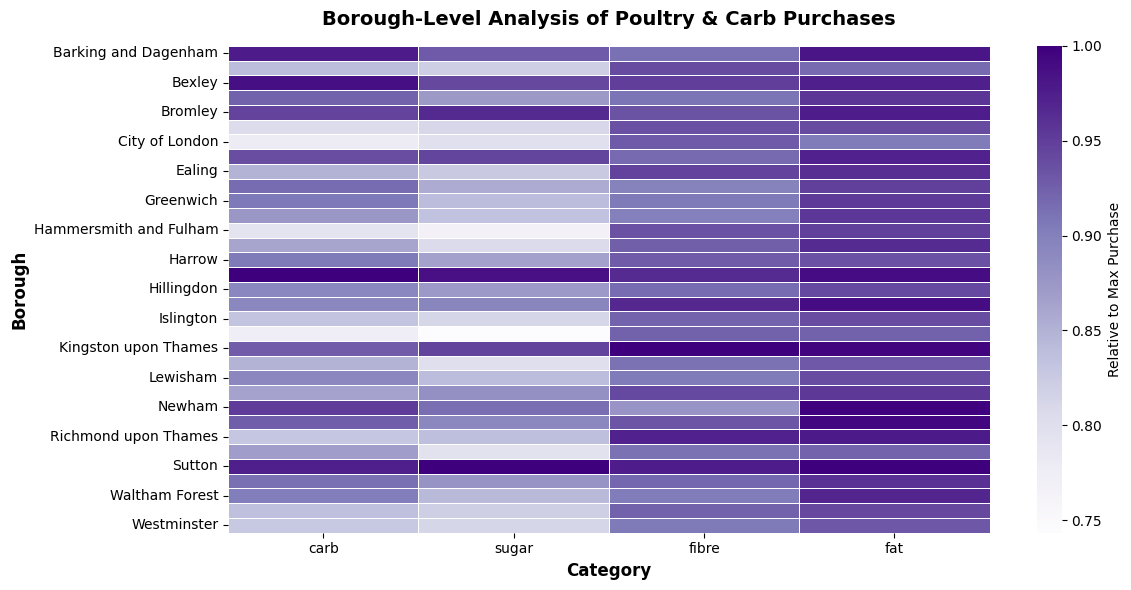

In [33]:
borough_col = "local authority name"
sugar_col = "sugar"
carb_col = "carb"
fibre_col ="fibre"
fat_col = "fat"
poultry_col = "poultry"
borough_trends = dfs.groupby(borough_col)[[carb_col,sugar_col, fibre_col,fat_col]].sum().reset_index()

borough_trends[fat_col] = borough_trends[fat_col] / borough_trends[fat_col].max()
borough_trends[carb_col] = borough_trends[carb_col] / borough_trends[carb_col].max()
borough_trends[fibre_col] = borough_trends[fibre_col] / borough_trends[fibre_col].max()
borough_trends[sugar_col] = borough_trends[sugar_col] / borough_trends[sugar_col].max()

df_melted = borough_trends.melt(id_vars=borough_col, var_name="Category", value_name="Normalized Value")

plt.figure(figsize=(12, 6))
heatmap = sns.heatmap(
    borough_trends.set_index(borough_col),
    cmap="Purples",
    linewidths=0.5,
    cbar_kws={'label': 'Relative to Max Purchase'}
)

plt.xlabel("Category", fontsize=12, fontweight="bold")
plt.ylabel("Borough", fontsize=12, fontweight="bold")
plt.title("Borough-Level Analysis of Poultry & Carb Purchases", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [34]:
l = dfs["area_id"]
l = list(l.unique())
dd = pd.read_excel("/content/education.xlsx")
d = list(dd["Code"])

common_values = list(set(l) & set(d))
print(common_values, len(common_values))
for i in range(len(l)):
  if l[i] not in d:
    print(l)

['E09000007', 'E09000023', 'E09000028', 'E09000014', 'E09000011', 'E09000030', 'E09000016', 'E09000005', 'E09000015', 'E09000012', 'E09000009', 'E09000020', 'E09000033', 'E09000026', 'E09000019', 'E09000021', 'E09000024', 'E09000022', 'E09000010', 'E09000002', 'E09000001', 'E09000018', 'E09000004', 'E09000025', 'E09000029', 'E09000017', 'E09000032', 'E09000013', 'E09000027', 'E09000003', 'E09000006', 'E09000031', 'E09000008'] 33


In [35]:
for i in range(len(c_df.columns)):
  print(c_df.columns[i])
print(len(c_df.columns))

local authority name
area_id
weight
weight_perc2.5
weight_perc25
weight_perc50
weight_perc75
weight_perc97.5
weight_std
weight_ci95
volume
volume_perc2.5
volume_perc25
volume_perc50
volume_perc75
volume_perc97.5
volume_std
volume_ci95
fat
fat_perc2.5
fat_perc25
fat_perc50
fat_perc75
fat_perc97.5
fat_std
fat_ci95
saturate
saturate_perc2.5
saturate_perc25
saturate_perc50
saturate_perc75
saturate_perc97.5
saturate_std
saturate_ci95
salt
salt_perc2.5
salt_perc25
salt_perc50
salt_perc75
salt_perc97.5
salt_std
salt_ci95
sugar
sugar_perc2.5
sugar_perc25
sugar_perc50
sugar_perc75
sugar_perc97.5
sugar_std
sugar_ci95
protein
protein_perc2.5
protein_perc25
protein_perc50
protein_perc75
protein_perc97.5
protein_std
protein_ci95
carb
carb_perc2.5
carb_perc25
carb_perc50
carb_perc75
carb_perc97.5
carb_std
carb_ci95
fibre
fibre_perc2.5
fibre_perc25
fibre_perc50
fibre_perc75
fibre_perc97.5
fibre_std
fibre_ci95
alcohol
alcohol_perc2.5
alcohol_perc25
alcohol_perc50
alcohol_perc75
alcohol_perc97.5
alcoho

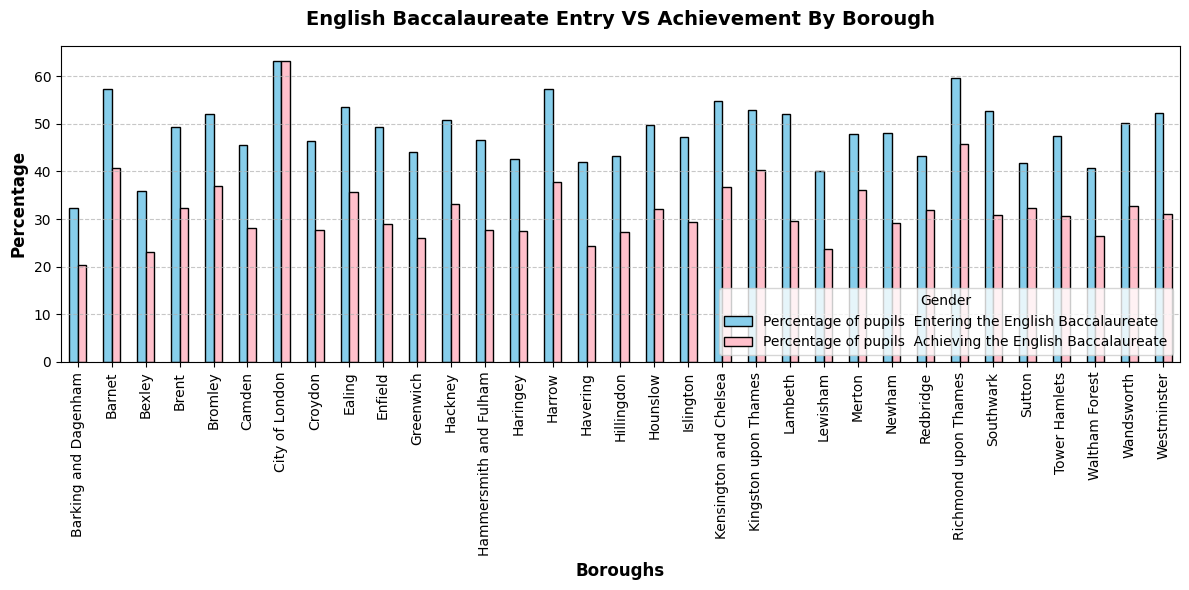

In [36]:


# # Create the bar chart
# plt.figure(figsize=(12, 6))

# # Bar width
# # bar_width = 0.35

# # r1 = range(len(dfs))
# # r2 = [x + bar_width for x in r1]
# # Plot the bars
# plt.bar(r1, c_df['Percentage of pupils  Entering the English Baccalaureate'], color='#7f6d5f', width=bar_width, edgecolor='white', label='Percent Entering')
# plt.bar(r2, c_df['Percentage of pupils  Achieving the English Baccalaureate'], color='#557f2d', width=bar_width, edgecolor='white', label='Percent Achieving')


# plt.xlabel('Borough', fontweight='bold')
# plt.ylabel('Percentage', fontweight='bold')
# plt.title('Pupil Baccalaureate Entry and Achievement by Borough', fontsize=14, fontweight='bold')
# plt.xticks([r + bar_width / 2 for r in range(len(dfs))], c_df['local authority name'])
# plt.legend()

# plt.tight_layout()
# plt.show()

gender_distribution = c_df.groupby("local authority name")[["Percentage of pupils  Entering the English Baccalaureate", "Percentage of pupils  Achieving the English Baccalaureate"]].sum()

gender_distribution.plot(kind="bar", figsize=(12, 6), color=['skyblue', 'pink'], edgecolor="black")
plt.xlabel("Boroughs", fontsize=12, fontweight="bold")
plt.ylabel("Percentage", fontsize=12, fontweight="bold")
plt.title("English Baccalaureate Entry VS Achievement By Borough", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=90)
plt.legend(title="Gender", loc="lower right")
plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()



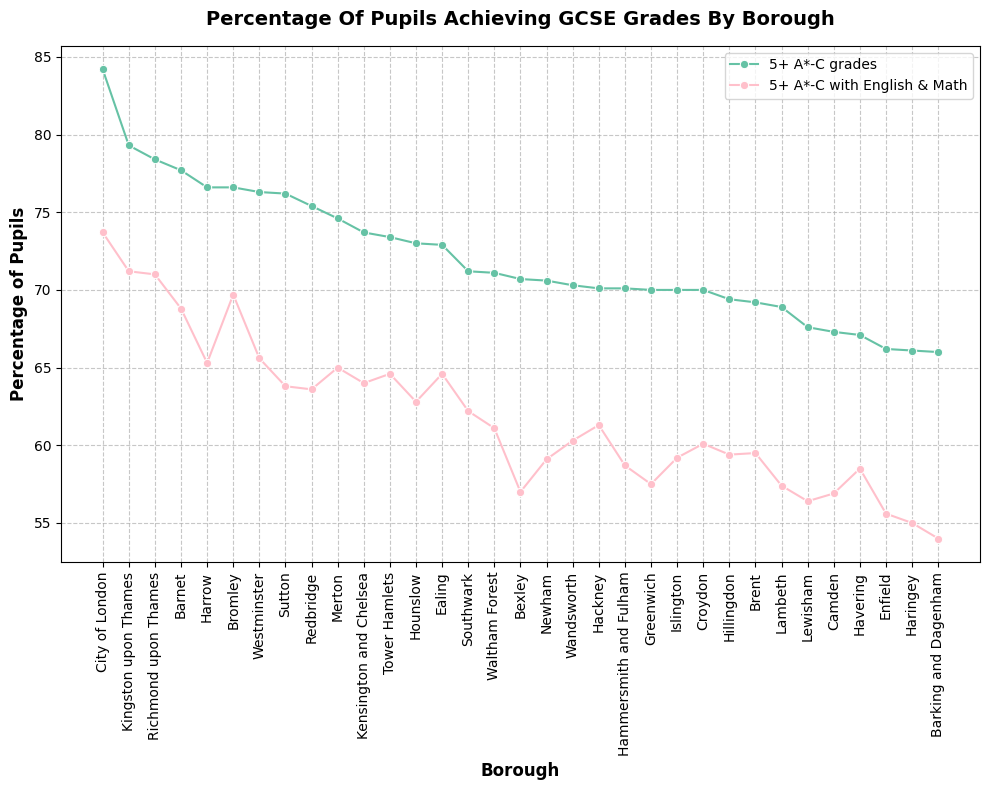

In [37]:

# borough_with_highest_gcse = c_df.loc[dd['Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs'].idxmax()]

c_df = c_df.sort_values(by='Percentage of pupils achieving 5+ A*-C grades', ascending=False)

colors = sns.color_palette("Set2", 5)  # Set2 is a good, eye-friendly palette

plt.figure(figsize=(10, 8))

sns.lineplot(x=c_df['local authority name'], y=c_df['Percentage of pupils achieving 5+ A*-C grades'], label='5+ A*-C grades', color=colors[0], marker='o')
# sns.lineplot(x=c_df['local authority name'], y=c_df['Percentage of pupils achieving 5+ A*-G grades'], label='5+ A*-G grades', color=colors[1], marker='o')
# sns.lineplot(x=c_df['local authority name'], y=c_df['Percentage of pupils achieving 5+ A*-G grades inc. English and mathematics GCSEs'], label='5+ A*-G with English & Math', color=colors[2], marker='o')
sns.lineplot(x=c_df['local authority name'], y=c_df['Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs'], label='5+ A*-C with English & Math', color="pink", marker='o')
# sns.lineplot(x=c_df['local authority name'], y=c_df['Percentage of pupils achieving A*-C in English and mathematics GCSEs'], label='A*-C in English & Math', color=colors[4], marker='o')

plt.xticks(rotation=90)

plt.xlabel("Borough", fontsize=12, fontweight="bold")
plt.ylabel("Percentage of Pupils", fontsize=12, fontweight="bold")
plt.title("Percentage Of Pupils Achieving GCSE Grades By Borough", fontsize=14, fontweight="bold", pad=15)

plt.grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()

plt.legend()

plt.show()


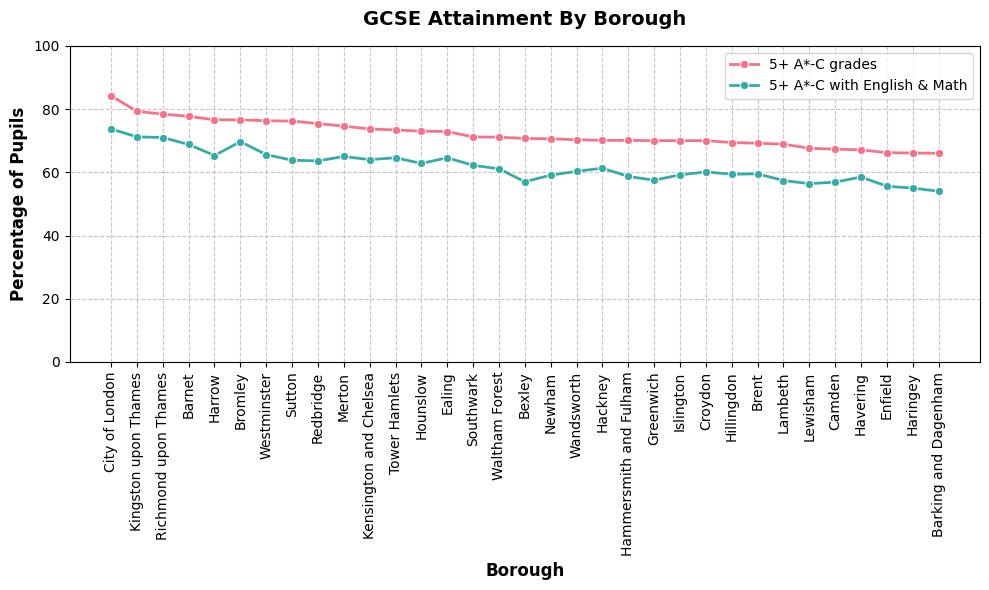

In [38]:
c_df = c_df.sort_values(by='Percentage of pupils achieving 5+ A*-C grades', ascending=False)

colors = sns.color_palette("husl", 2)

plt.figure(figsize=(10, 6))

sns.lineplot(x=c_df['local authority name'],
             y=c_df['Percentage of pupils achieving 5+ A*-C grades'],
             label='5+ A*-C grades',
             color=colors[0],
             marker='o',
             linewidth=2)

sns.lineplot(x=c_df['local authority name'],
             y=c_df['Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs'],
             label='5+ A*-C with English & Math',
             color=colors[1],
             marker='o',
             linewidth=2)

plt.xticks(rotation=90)

plt.ylim(0, 100)

plt.xlabel("Borough", fontsize=12, fontweight="bold")
plt.ylabel("Percentage of Pupils", fontsize=12, fontweight="bold")
plt.title("GCSE Attainment By Borough", fontsize=14, fontweight="bold", pad=15)

plt.grid( linestyle="--", alpha=0.7)

plt.legend()

plt.tight_layout()

plt.show()


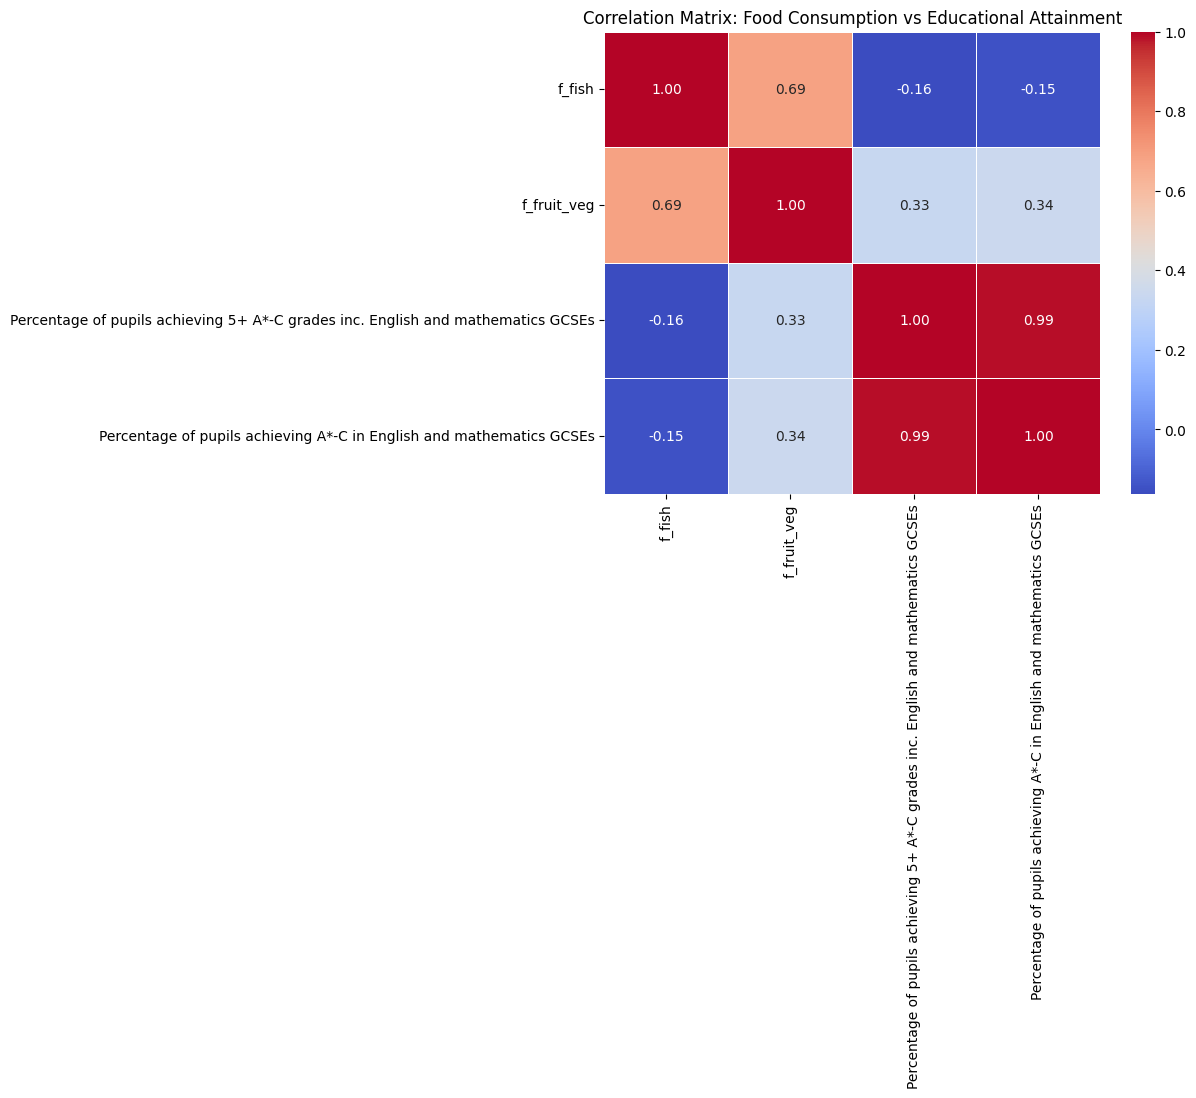

In [39]:
data = c_df[[
    "f_fish",
    "f_fruit_veg",
    "Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs",
    "Percentage of pupils achieving A*-C in English and mathematics GCSEs"
]].dropna()

correlation_matrix = data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: Food Consumption vs Educational Attainment")
plt.show()


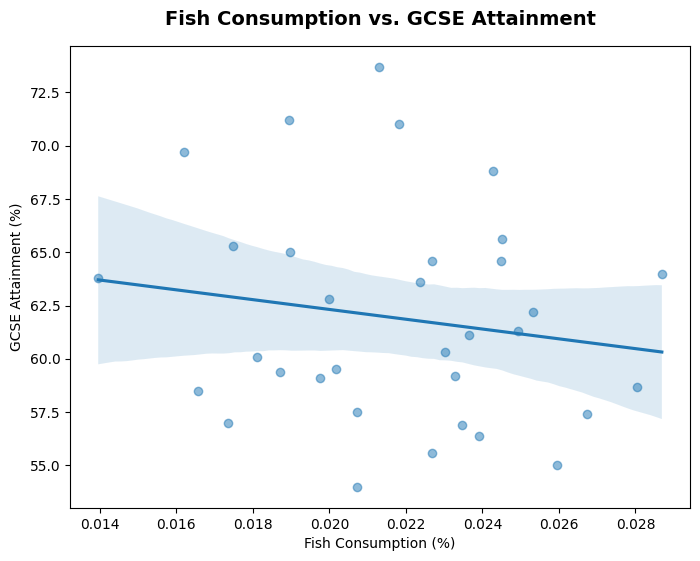

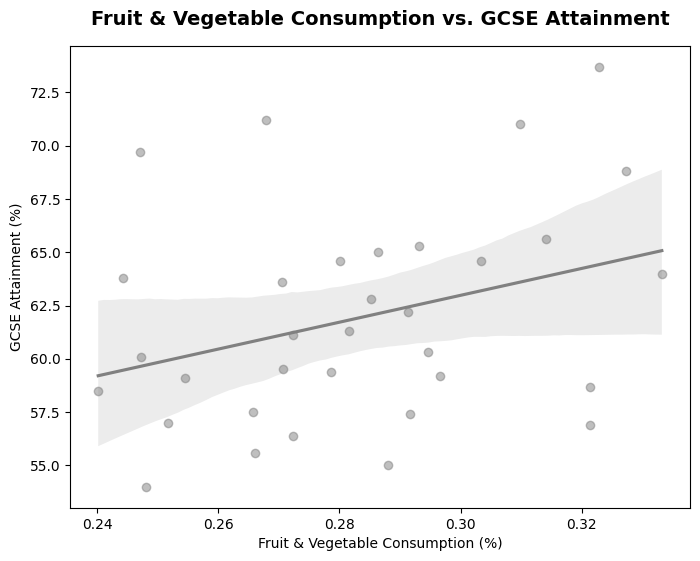

In [40]:
df = pd.read_excel("combined data.xlsx")

df = df.dropna()

fish_col = "f_fish"
fruit_veg_col = "f_fruit_veg"
attainment_col = "Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs"

plt.figure(figsize=(8, 6))
sns.regplot(x=df[fish_col], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Fish Consumption (%)")
plt.ylabel("GCSE Attainment (%)")
plt.title("Fish Consumption vs. GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

plt.figure(figsize=(8, 6))
sns.regplot(x=df[fruit_veg_col], y=df[attainment_col], scatter_kws={"alpha": 0.5}, color='gray')
plt.xlabel("Fruit & Vegetable Consumption (%)")
plt.ylabel("GCSE Attainment (%)")
plt.title("Fruit & Vegetable Consumption vs. GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()


In [41]:
for i in range(df.shape[-1]):
  print(df.columns[i])

local authority name
area_id
weight
weight_perc2.5
weight_perc25
weight_perc50
weight_perc75
weight_perc97.5
weight_std
weight_ci95
volume
volume_perc2.5
volume_perc25
volume_perc50
volume_perc75
volume_perc97.5
volume_std
volume_ci95
fat
fat_perc2.5
fat_perc25
fat_perc50
fat_perc75
fat_perc97.5
fat_std
fat_ci95
saturate
saturate_perc2.5
saturate_perc25
saturate_perc50
saturate_perc75
saturate_perc97.5
saturate_std
saturate_ci95
salt
salt_perc2.5
salt_perc25
salt_perc50
salt_perc75
salt_perc97.5
salt_std
salt_ci95
sugar
sugar_perc2.5
sugar_perc25
sugar_perc50
sugar_perc75
sugar_perc97.5
sugar_std
sugar_ci95
protein
protein_perc2.5
protein_perc25
protein_perc50
protein_perc75
protein_perc97.5
protein_std
protein_ci95
carb
carb_perc2.5
carb_perc25
carb_perc50
carb_perc75
carb_perc97.5
carb_std
carb_ci95
fibre
fibre_perc2.5
fibre_perc25
fibre_perc50
fibre_perc75
fibre_perc97.5
fibre_std
fibre_ci95
alcohol
alcohol_perc2.5
alcohol_perc25
alcohol_perc50
alcohol_perc75
alcohol_perc97.5
alcoho

In [42]:
correlation_coefficient = df["f_tea_coffee"].corr(df["f_beer"])
print(f"Correlation Coefficient : {correlation_coefficient}")


Correlation Coefficient : -0.48611860395501333


The correlation between poultry and meat_Red is: 0.8110739576613158


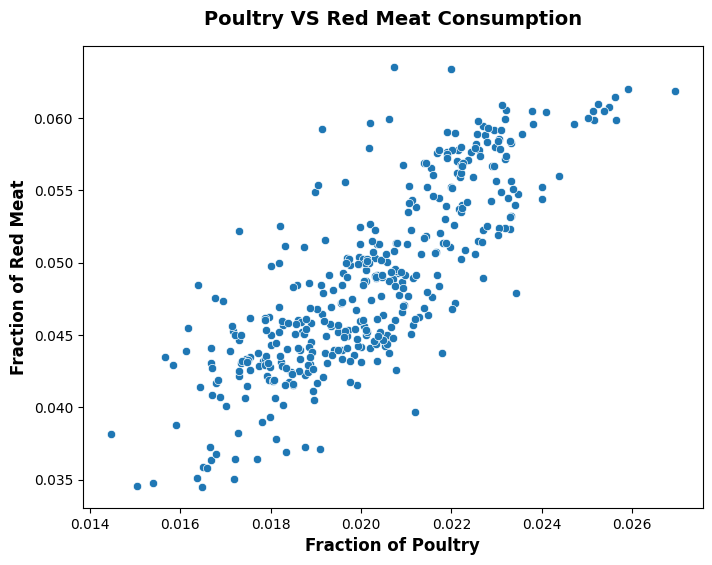

In [43]:
correlation = dfs['f_poultry'].corr(dfs['f_meat_red'])

print(f"The correlation between poultry and meat_Red is: {correlation}")

plt.figure(figsize=(8, 6))
sns.scatterplot(x='f_poultry', y='f_meat_red', data=dfs)
plt.title('Poultry VS Red Meat Consumption', fontsize=14, fontweight="bold", pad=15 )
plt.xlabel('Fraction of Poultry', fontsize=12, fontweight="bold")
plt.ylabel('Fraction of Red Meat', fontsize=12, fontweight="bold")
plt.show()



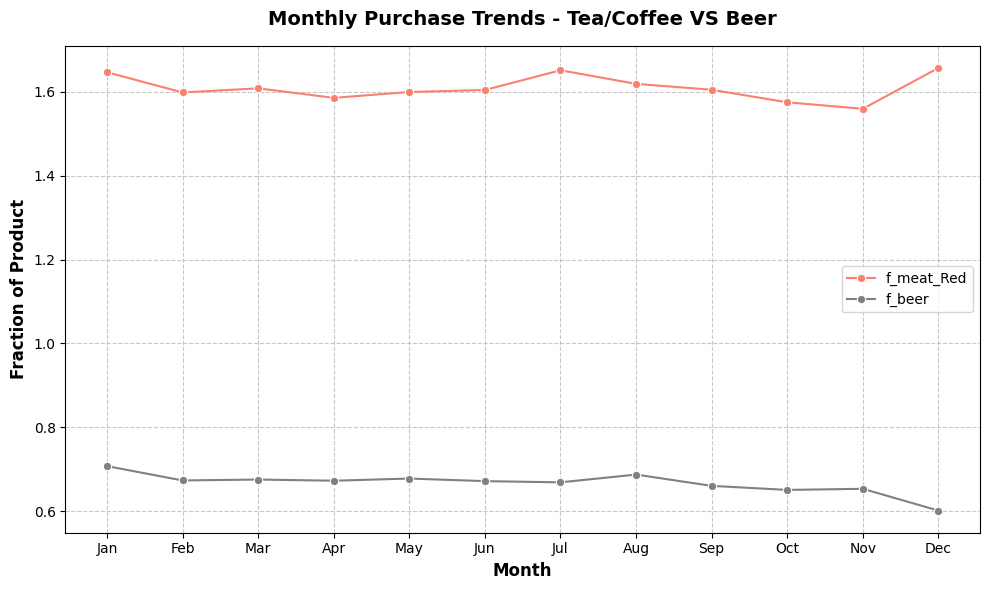

In [44]:

monthly_meat_sales = dfs.groupby('month')['f_meat_red'].sum().reset_index()
monthly_poultry_sales = dfs.groupby('month')['f_poultry'].sum().reset_index()

months_ordered = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

monthly_meat_sales['month'] = pd.Categorical(monthly_meat_sales['month'], categories=months_ordered, ordered=True)
monthly_poultry_sales['month'] = pd.Categorical(monthly_poultry_sales['month'], categories=months_ordered, ordered=True)

monthly_meat_sales = monthly_meat_sales.sort_values('month')
monthly_poultry_sales = monthly_poultry_sales.sort_values('month')

plt.figure(figsize=(10, 6))

sns.lineplot(x='month', y='f_meat_red', data=monthly_meat_sales, label='f_meat_Red', marker='o', color ="salmon")

sns.lineplot(x='month', y='f_poultry', data=monthly_poultry_sales, label='f_beer', marker='o', color="gray")

plt.xlabel('Month', fontsize=12,  fontweight="bold")
plt.ylabel('Fraction of Product', fontsize=12,  fontweight="bold")
plt.title('Monthly Purchase Trends - Tea/Coffee VS Beer', fontsize=14, fontweight="bold", pad=15)

plt.legend()
plt.xticks()
plt.tight_layout()
plt.grid(linestyle="--", alpha=0.7)
plt.show()


Correlation Coefficient between fibre Consumption and GCSE Attainment: 0.46962702664004713


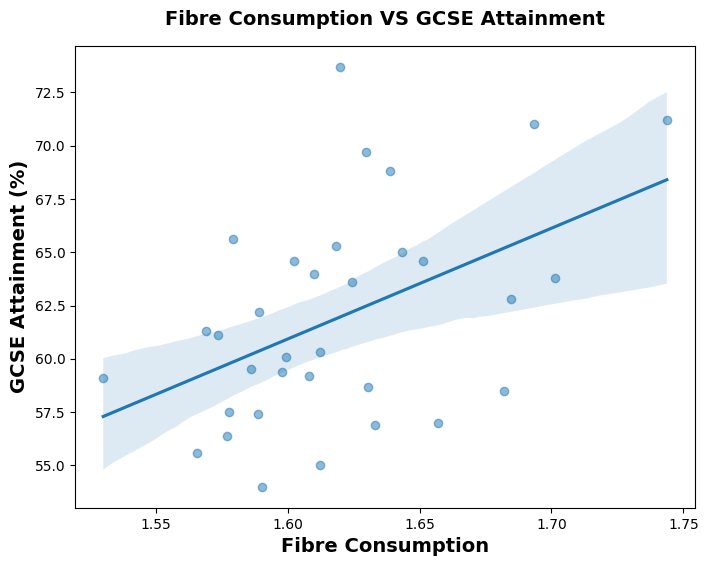

In [45]:

attainment_col = "Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs"
correlation_coefficient = df["fibre"].corr(df[attainment_col])
print(f"Correlation Coefficient between fibre Consumption and GCSE Attainment: {correlation_coefficient}")

plt.figure(figsize=(8, 6))
sns.regplot(x=df["fibre"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Fibre Consumption",  fontsize=14, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=14, fontweight="bold")
plt.title("Fibre Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

In [46]:

fibre_columns = [col for col in df.columns if "fibre" in col.lower()]
print(fibre_columns)

for col in fibre_columns:
    correlation = df[col].corr(df[attainment_col])
    print(f"{col}: {correlation}")


['fibre', 'fibre_perc2.5', 'fibre_perc25', 'fibre_perc50', 'fibre_perc75', 'fibre_perc97.5', 'fibre_std', 'fibre_ci95', 'energy_fibre', 'energy_fibre_perc2.5', 'energy_fibre_perc25', 'energy_fibre_perc50', 'energy_fibre_perc75', 'energy_fibre_perc97.5', 'energy_fibre_std', 'energy_fibre_ci95', 'f_energy_fibre']
fibre: 0.46962702664004713
fibre_perc2.5: nan
fibre_perc25: nan
fibre_perc50: 0.07605827662243246
fibre_perc75: 0.347686891263788
fibre_perc97.5: 0.4671722235501482
fibre_std: 0.5011828577494136
fibre_ci95: 0.4930041572228361
energy_fibre: 0.5214931773751461
energy_fibre_perc2.5: nan
energy_fibre_perc25: nan
energy_fibre_perc50: 0.5443771619504599
energy_fibre_perc75: 0.3986837223864709
energy_fibre_perc97.5: 0.5363615836195172
energy_fibre_std: 0.5239195648003161
energy_fibre_ci95: 0.49615936590196325
f_energy_fibre: 0.48558190906111115


/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Correlation Coefficient between Red Meat Consumption and GCSE Attainment: -0.49076786556716495


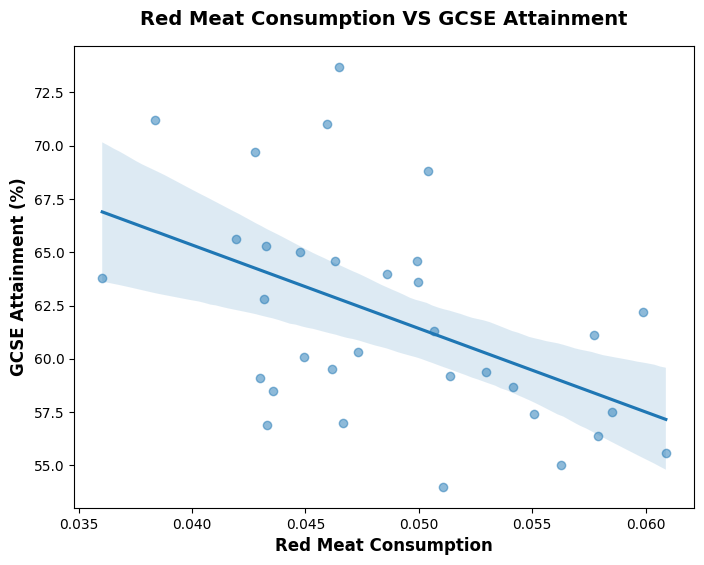

In [47]:
correlation_coefficient = df["f_meat_red"].corr(df[attainment_col])
print(f"Correlation Coefficient between Red Meat Consumption and GCSE Attainment: {correlation_coefficient}")

plt.figure(figsize=(8, 6))
sns.regplot(x=df["f_meat_red"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Red Meat Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Red Meat Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

Correlation Coefficient between Poultry Consumption and GCSE Attainment: -0.573995305162751


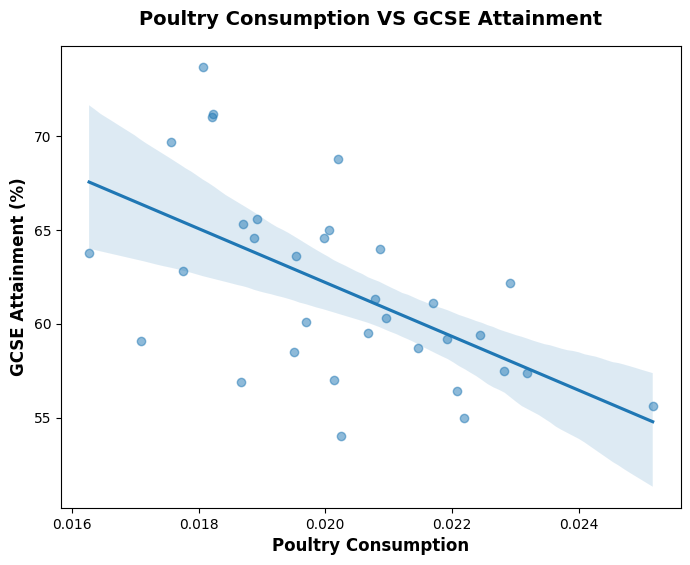

In [48]:
correlation_coefficient = df["f_poultry"].corr(df[attainment_col])
print(f"Correlation Coefficient between Poultry Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["f_poultry"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Poultry Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Poultry Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

In [49]:
correlation_coefficient = df["f_meat_red"].corr(df["f_meat_red"])
print(f"Correlation Coefficient between Red Meat Consumption and poultry: {correlation_coefficient}")


Correlation Coefficient between Red Meat Consumption and poultry: 1.0


Correlation Coefficient between carbs Consumption and GCSE Attainment: -0.26387542985253953


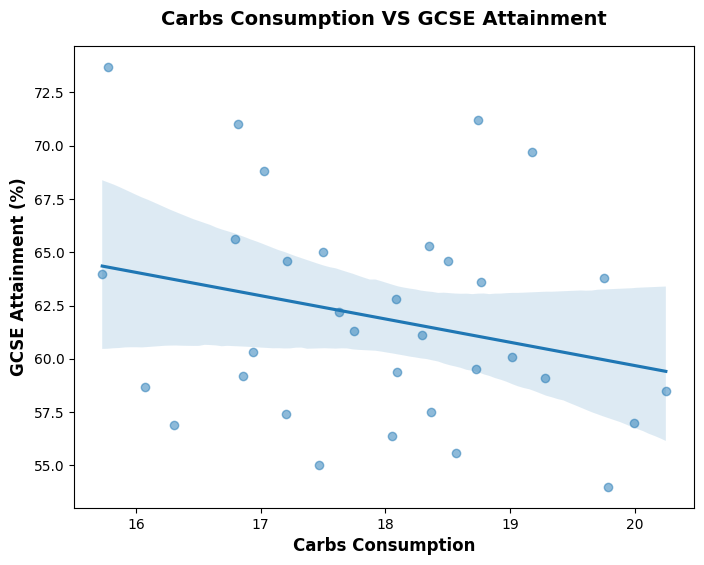

In [50]:
correlation_coefficient = df["carb"].corr(df[attainment_col])
print(f"Correlation Coefficient between carbs Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["carb"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Carbs Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Carbs Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

Correlation Coefficient between fish Consumption and GCSE Attainment: -0.16168595028502344


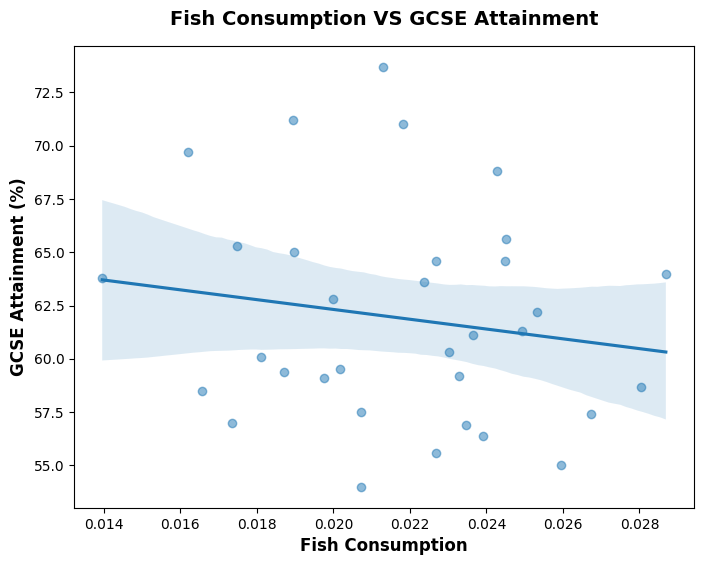

In [51]:
correlation_coefficient = df["f_fish"].corr(df[attainment_col])
print(f"Correlation Coefficient between fish Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["f_fish"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Fish Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Fish Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

Correlation Coefficient between sweet Consumption and GCSE Attainment: -0.054470627938633644


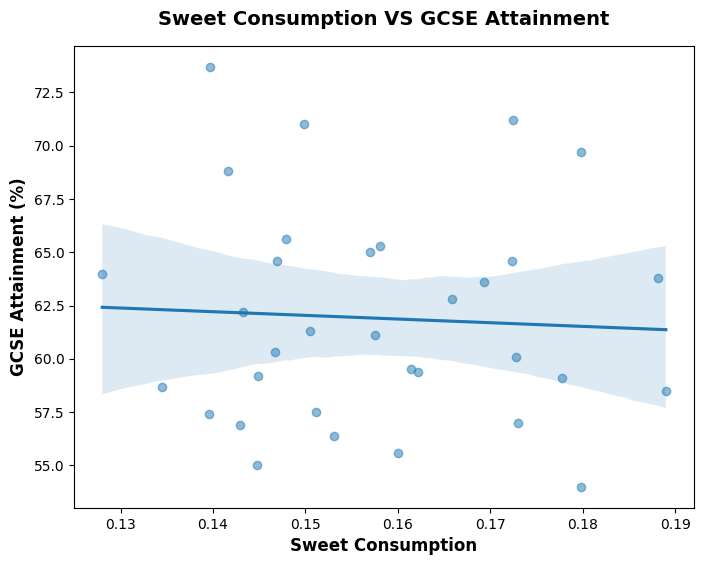

In [52]:
correlation_coefficient = df["f_sweets"].corr(df[attainment_col])
print(f"Correlation Coefficient between sweet Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["f_sweets"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Sweet Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Sweet Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

In [53]:
for i in range(len(df.columns)):
  print(df.columns[i])

local authority name
area_id
weight
weight_perc2.5
weight_perc25
weight_perc50
weight_perc75
weight_perc97.5
weight_std
weight_ci95
volume
volume_perc2.5
volume_perc25
volume_perc50
volume_perc75
volume_perc97.5
volume_std
volume_ci95
fat
fat_perc2.5
fat_perc25
fat_perc50
fat_perc75
fat_perc97.5
fat_std
fat_ci95
saturate
saturate_perc2.5
saturate_perc25
saturate_perc50
saturate_perc75
saturate_perc97.5
saturate_std
saturate_ci95
salt
salt_perc2.5
salt_perc25
salt_perc50
salt_perc75
salt_perc97.5
salt_std
salt_ci95
sugar
sugar_perc2.5
sugar_perc25
sugar_perc50
sugar_perc75
sugar_perc97.5
sugar_std
sugar_ci95
protein
protein_perc2.5
protein_perc25
protein_perc50
protein_perc75
protein_perc97.5
protein_std
protein_ci95
carb
carb_perc2.5
carb_perc25
carb_perc50
carb_perc75
carb_perc97.5
carb_std
carb_ci95
fibre
fibre_perc2.5
fibre_perc25
fibre_perc50
fibre_perc75
fibre_perc97.5
fibre_std
fibre_ci95
alcohol
alcohol_perc2.5
alcohol_perc25
alcohol_perc50
alcohol_perc75
alcohol_perc97.5
alcoho

Correlation Coefficient between Calorie Consumption and GCSE Attainment: -0.46180507135077775


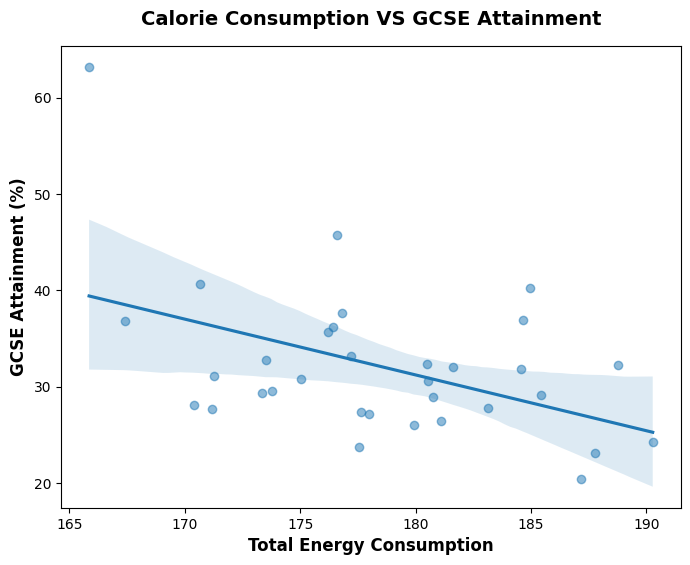

In [54]:
attainment_col = "Percentage of pupils  Achieving the English Baccalaureate"

correlation_coefficient = df["energy_tot"].corr(df[attainment_col])
print(f"Correlation Coefficient between Calorie Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["energy_tot"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Total Energy Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Calorie Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

Correlation Coefficient between sugar Consumption and GCSE Attainment: -0.21621708497262915


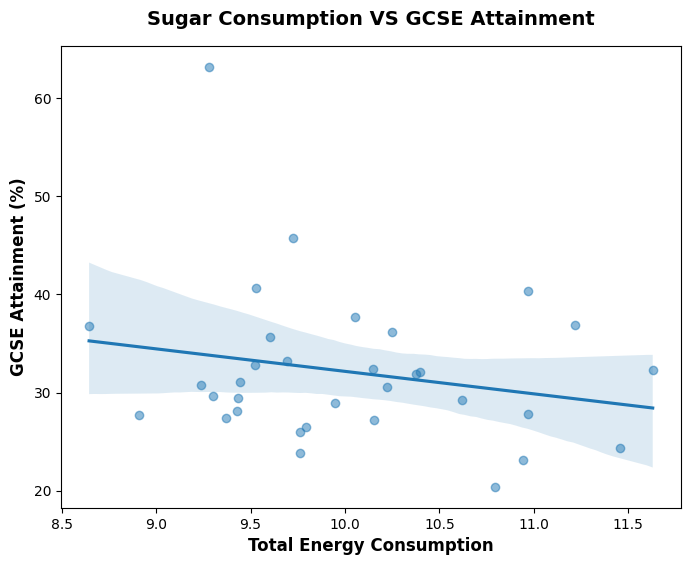

In [55]:
attainment_col = "Percentage of pupils  Achieving the English Baccalaureate"

correlation_coefficient = df["sugar"].corr(df[attainment_col])
print(f"Correlation Coefficient between sugar Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["sugar"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Total Energy Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Sugar Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

Correlation Coefficient between fruits Consumption and GCSE Attainment: 0.4899513956954589


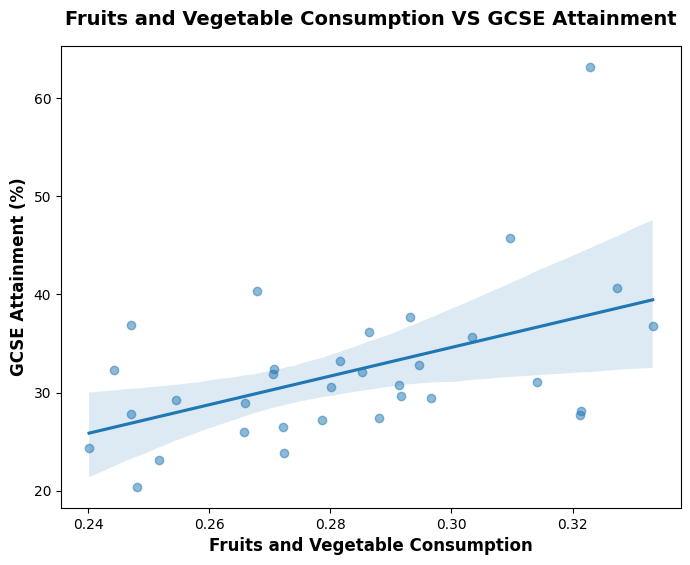

In [56]:
attainment_col = "Percentage of pupils  Achieving the English Baccalaureate"

correlation_coefficient = df["f_fruit_veg"].corr(df[attainment_col])
print(f"Correlation Coefficient between fruits Consumption and GCSE Attainment: {correlation_coefficient}")
plt.figure(figsize=(8, 6))
sns.regplot(x=df["f_fruit_veg"], y=df[attainment_col], scatter_kws={"alpha": 0.5})
plt.xlabel("Fruits and Vegetable Consumption", fontsize=12, fontweight="bold")
plt.ylabel("GCSE Attainment (%)", fontsize=12, fontweight="bold")
plt.title("Fruits and Vegetable Consumption VS GCSE Attainment", fontsize=14, fontweight="bold", pad=15)
plt.show()

In [57]:
avg_entering = df["Percentage of pupils  Entering the English Baccalaureate"].mean()
avg_achieving = df["Percentage of pupils  Achieving the English Baccalaureate"].mean()

print(f"Average Percentage of Pupils Entering EBacc: {avg_entering:.2f}%")
print(f"Average Percentage of Pupils Achieving EBacc: {avg_achieving:.2f}%")


Average Percentage of Pupils Entering EBacc: 48.22%
Average Percentage of Pupils Achieving EBacc: 32.12%


In [ ]:
avg_achieving = df["Percentage of pupils  Achieving the gcse"].mean()

print(f"Average Percentage of Pupils Achieving gsce: {avg_achieving:.2f}%")


In [61]:

avg_gcse_math_eng = df["Percentage of pupils achieving 5+ A*-C grades"].mean()

print(f"Average Percentage of Pupils Achieving 5+ A*-C grades in English and Maths GCSEs: {avg_gcse_math_eng:.2f}%")


Average Percentage of Pupils Achieving 5+ A*-C grades in English and Maths GCSEs: 72.13%
